# Кемерово: кварталы и показатели BlocksNet
Практика №2 курса «Технологии искусственного интеллекта в урбанистике».
Территория: **Кемерово, Кемеровская область — Кузбасс, Россия**.

Ноутбук подготовлен для **BlocksNet 1.0.0a9**, Python 3.10. Выполнение агентом разрешено пользователем 30.10.2026; результаты сохраняются в ячейках.
Загрузку и расчёты запускает пользователь по одной ячейке. Не используйте «Выполнить всё».

Источники: [практика 1](https://mvin8.github.io/ai-technologies-in-urbanism/content/practice/practice-01.html),
[практика 2](https://mvin8.github.io/ai-technologies-in-urbanism/content/practice/practice-02.html),
[BlocksNet pipeline](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb),
[релиз a9](https://pypi.org/project/blocksnet/1.0.0a9/).
У актуального примера путь импорта доступности отличается от a9: здесь используется
`blocksnet.analysis.network.accessibility`.

Порядок: окружение → граница → исходные слои → кварталы → **остановка и обсуждение метрик** →
землепользование → готовый граф и время → здания → школы → обеспеченность → плотность →
морфотипы → доступность → экспорт и проверка. HTML создаётся отдельным этапом после расчётов.

## 1. Окружение и пути
В VS Code нажмите «Выбрать ядро» → Python из `.venv/Scripts/python.exe` этого проекта.
Первая ячейка только импортирует библиотеки и создаёт папки результатов, без сетевых запросов.
`REFRESH=False` сохраняет повторное использование исходных GeoJSON.
Разрешения на загрузку, подтверждение границы и переход к метрикам по умолчанию выключены.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from enum import Enum
import importlib.metadata as metadata
import json, hashlib, urllib.request, zipfile, math
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
from shapely.geometry import LineString
from IPython.display import display, Markdown
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.relations import calculate_accessibility_matrix, validate_accessibility_graph
from blocksnet.analysis.provision import competitive_provision
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network.accessibility import area_accessibility
from blocksnet.config import service_types_config
from blocksnet.enums import LandUse

assert metadata.version('blocksnet') == '1.0.0a9'
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
BASE = ROOT / 'data' / 'kemerovo'
RAW, PROCESSED, RESULTS = [BASE / s for s in ('raw', 'processed', 'results')]
for folder in (RAW, PROCESSED, RESULTS): folder.mkdir(parents=True, exist_ok=True)
QUERY = 'Кемерово, Кемеровская область — Кузбасс, Россия'
ALLOW_DOWNLOAD = True  # Включить только перед своим запуском загрузки.
BOUNDARY_CONFIRMED = False  # Включить после просмотра границы.
CONTINUE_AFTER_BLOCKS = False  # Включить только после обсуждения кварталов и метрик.
REFRESH = False
versions = {n: metadata.version(n) for n in ('blocksnet','numpy','pandas','geopandas','shapely','osmnx','iduedu')}
print(ROOT)
display(pd.Series(versions, name='version'))
ox.settings.use_cache = True
ox.settings.cache_folder = str(BASE / 'osm_cache')
ox.settings.requests_timeout = 180
ox.settings.requests_timeout = 90
ox.settings.http_user_agent = 'ITMOAI-Kemerovo-Coursework/1.0 (educational OSM analysis)'
ox.settings.overpass_rate_limit = False
ox.settings.log_console = False

ox.settings.overpass_url = 'https://maps.mail.ru/osm/tools/overpass/api'

# Контрольная численность сообщена пользователем; год и внешний источник не указаны.
POPULATION_TOTAL = 542_928
POPULATION_SOURCE = 'Численность Кемерово, указанная пользователем 30.10.2026; год статистики не указан'


C:\Users\kkosh\OneDrive\Документы\ITMOAI\python-package-boilerplate\.venv\lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


C:\Users\kkosh\OneDrive\Документы\ITMOAI\python-package-boilerplate


blocksnet    1.0.0a9
numpy          2.2.6
pandas         2.2.3
geopandas      1.1.4
shapely        2.1.2
osmnx          2.0.7
iduedu         0.4.1
Name: version, dtype: object

In [2]:
def require_download():
    if not ALLOW_DOWNLOAD:
        raise RuntimeError('Загрузка выключена. Разрешите её в настройках и выполните ячейку вручную.')

def require_metrics():
    if not CONTINUE_AFTER_BLOCKS:
        raise RuntimeError('Остановка после кварталов. Сначала обсудите метрики, затем измените флаг.')

def save_json(obj, path):
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def save_geo(gdf, path, id_name=None):
    out = gdf.copy()
    if out.crs is None: raise ValueError('Не задан CRS')
    if id_name:
        out[id_name] = out.index
    for col in out.select_dtypes(include='object'):
        if col == out.geometry.name: continue
        out[col] = out[col].map(lambda x: x.value if isinstance(x, Enum) else
                                json.dumps(x, ensure_ascii=False) if isinstance(x, (list, dict, tuple)) else x)
    numeric = out.select_dtypes(include='number').columns
    out[numeric] = out[numeric].replace([np.inf, -np.inf], np.nan)
    if len(out):
        out.to_crs(4326).to_file(path, driver='GeoJSON', index=False)
    else:
        save_json({'type':'FeatureCollection', 'features':[]}, path)
    check = gpd.read_file(path)
    assert len(check) == len(out), path
    if id_name and len(out): assert check[id_name].is_unique

def read_blocks(path, crs):
    result = gpd.read_file(path).to_crs(crs)
    result['block_id'] = result['block_id'].astype(int)
    return result.set_index('block_id')

def clean_polygons(gdf):
    out = gdf.loc[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
    out.geometry = out.geometry.make_valid()
    out = out.explode(index_parts=False)
    return out.loc[out.geom_type.isin(['Polygon','MultiPolygon'])].copy()

def show_metric(gdf, column, categorical=False):
    if not gdf[column].notna().any():
        print(column, ': нет значений; см. ограничения и качество исходных данных')
        return
    ax = gdf.plot(column=column, legend=True, categorical=categorical, figsize=(11,7),
                  missing_kwds={'color':'lightgrey','label':'Нет данных'})
    ax.set_title(column); ax.set_axis_off(); plt.show()

def show_numeric(gdf, columns):
    display(gdf[columns].describe().T)
    for col in columns: show_metric(gdf, col)

def get_osm_layer(name, tags):
    path = RAW / (name + '.geojson')
    if path.exists() and not REFRESH: return gpd.read_file(path)
    require_download()
    from osmnx._errors import InsufficientResponseError
    try:
        layer = ox.features_from_polygon(boundary.to_crs(4326).union_all().convex_hull, tags=tags).reset_index()
        layer = layer.loc[layer.intersects(boundary.to_crs(4326).union_all())].copy()
        layer['osm_uid'] = layer['element'].astype(str) + '/' + layer['id'].astype(str)
    except InsufficientResponseError:
        layer = gpd.GeoDataFrame(geometry=[], crs=4326)
        print('OSM не вернул объектов:', name)
    save_geo(layer, path)
    save_json({'source':'OpenStreetMap contributors / OSMnx', 'query':QUERY, 'tags':tags,
               'retrieved_utc':datetime.now(timezone.utc).isoformat(), 'count':len(layer)},
              RAW / (name + '.metadata.json'))
    return layer

# Ограниченный транспортный адаптер для OSMnx 2.0.7: запросы идут по стандартному
# HTTPS без фиксации DNS и без рекурсивных повторов OSMnx. Проверка TLS включена.
# Используется внутренний интерфейс этой закреплённой версии OSMnx.
def bounded_overpass_request(data):
    import requests
    cache_dir = BASE / 'overpass_cache'
    cache_dir.mkdir(exist_ok=True)
    query = data['data']
    cache_key = hashlib.sha256((ox.settings.overpass_url + query).encode()).hexdigest()
    cache_path = cache_dir / (cache_key + '.json')
    if cache_path.exists():
        return json.loads(cache_path.read_text(encoding='utf-8'))
    require_download()
    print('Overpass:', ox.settings.overpass_url, 'query bytes:',len(query.encode()), flush=True)
    response = requests.post(ox.settings.overpass_url.rstrip('/')+'/interpreter',
        data=data, headers={'User-Agent':ox.settings.http_user_agent}, timeout=(15,90))
    response.raise_for_status()
    result = response.json()
    if 'remark' in result:
        raise RuntimeError('Overpass вернул неполный результат: '+result['remark'])
    assert 'elements' in result
    save_json(result, cache_path)
    print('Получено элементов OSM:', len(result['elements']), flush=True)
    return result

ox._overpass._overpass_request = bounded_overpass_request


## 2. Граница — первая проверка
Разрешите загрузку (`ALLOW_DOWNLOAD=True`), затем выполните следующую ячейку.
Результат геокодера — кандидат, а не автоматически подтверждённая территория.
Сравните контур с Кемерово; административная граница и застроенная территория могут различаться.
При неверном контуре остановитесь и уточните запрос. После просмотра поставьте
`BOUNDARY_CONFIRMED=True` в отдельной ячейке ниже.

In [3]:
boundary_path = RAW / 'boundary.geojson'
if boundary_path.exists() and not REFRESH:
    boundary = gpd.read_file(boundary_path)
else:
    require_download()
    boundary = ox.geocode_to_gdf(QUERY)
    save_geo(boundary, boundary_path)
    save_json({'source':'Nominatim / OpenStreetMap', 'query':QUERY,
               'retrieved_utc':datetime.now(timezone.utc).isoformat()}, RAW / 'boundary.metadata.json')
boundary = clean_polygons(boundary)
assert len(boundary) > 0
CRS = boundary.estimate_utm_crs()
boundary = boundary.to_crs(CRS)
display(boundary.drop(columns='geometry'))
display(boundary.to_crs(4326).explore(tiles='OpenStreetMap'))
print('Рабочий CRS:', CRS, 'Площадь границы, км²:', boundary.area.sum() / 1e6)

,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,85.909499,55.256576,86.292047,55.544921,216628034,relation,1312868,55.355091,86.087121,place,city,16,0.582463,city,Kemerovo,"Kemerovo, Kemerovsky Urban Okrug, Kemerovo Obl..."


Рабочий CRS: EPSG:32645 Площадь границы, км²: 319.8482631611598


In [4]:
# Измените на True только после визуальной проверки предыдущей карты.
BOUNDARY_CONFIRMED = True

## 3. Исходные слои из региональной выгрузки OSM
Публичные Overpass-серверы вернули SSL/413/504. Поэтому используется готовый региональный
PBF Кемеровской области: https://www.osmlab.ru/regions/RU-KEM.pbf (88 МБ).
Снимок и контрольная сумма записаны в `raw/RU-KEM.metadata.json`.
Источник данных остался OpenStreetMap. Полигональные relations и замкнутые ways собирает libosmium.
Объекты отбираются по пересечению с точной границей Кемерово.
Для графа берутся исходные OSM ways и **идентификаторы узлов**, в контексте выпуклой оболочки
города с буфером 1 км. Условие выбора автомобильных дорог соответствует preset drive OSMnx.
Вспомогательная реализация находится в `scripts/osm_local.py`, исходный учебный пакет не меняется.
При повторном запуске читаются сохранённые GeoJSON и исходный граф без повторной загрузки.


In [5]:
assert BOUNDARY_CONFIRMED, 'Сначала подтвердите границу'
tags = {
 'roads': {'highway':['construction','crossing','living_street','motorway','motorway_link',
    'motorway_junction','pedestrian','primary','primary_link','raceway','residential','road',
    'secondary','secondary_link','services','tertiary','tertiary_link','track','trunk',
    'trunk_link','turning_circle','turning_loop','unclassified'],
    'service':['living_street','emergency_access']},
 'railways': {'railway':'rail'},
 'water': {'riverbank':True,'reservoir':True,'basin':True,'dock':True,'canal':True,
    'pond':True,'natural':['water','bay'],'waterway':['river','canal','ditch'],
    'landuse':'basin','water':'lake'},
 'functional_zones': {'landuse':True}, 'buildings': {'building':True},
 'schools': {'amenity':'school'},
}

import sys, requests
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from scripts.osm_local import extract_city, graph_from_response
PBF_URL = 'https://www.osmlab.ru/regions/RU-KEM.pbf'
PBF_PATH = RAW / 'RU-KEM.pbf'
raw_paths = {name: RAW / (name+'.geojson') for name in tags}
response_path = RAW / 'drive_osm_response.json'
if all(path.exists() for path in raw_paths.values()) and response_path.exists() and not REFRESH:
    layers = {name:gpd.read_file(path).to_crs(CRS) for name,path in raw_paths.items()}
else:
    if not PBF_PATH.exists():
        require_download()
        with requests.get(PBF_URL,stream=True,timeout=(15,90)) as response:
            response.raise_for_status()
            part = PBF_PATH.with_suffix('.part')
            with part.open('wb') as target:
                for chunk in response.iter_content(1024*1024): target.write(chunk)
            expected = response.headers.get('Content-Length')
            if expected: assert part.stat().st_size == int(expected)
            part.replace(PBF_PATH)
            save_json({'source':PBF_URL,'last_modified':response.headers.get('Last-Modified'),
                'retrieved_utc':datetime.now(timezone.utc).isoformat(),
                'sha256':hashlib.sha256(PBF_PATH.read_bytes()).hexdigest()},
                RAW / 'RU-KEM.metadata.json')
    layers, drive_response, pbf_errors = extract_city(PBF_PATH,boundary,tags)
    save_json(drive_response,response_path)
    save_json(pbf_errors,RAW / 'pbf_geometry_errors.json')
    for name,layer in layers.items():
        save_geo(layer,raw_paths[name])
        save_json({'source':PBF_URL,'tags':tags[name],'count':len(layer),
            'retrieved_utc':datetime.now(timezone.utc).isoformat(),
            'note':'Regional PBF; exact city boundary intersection; libosmium area assembly'},
            RAW / (name+'.metadata.json'))
    layers = {name:layer.to_crs(CRS) for name,layer in layers.items()}
display(pd.Series({name:len(layer) for name,layer in layers.items()},name='objects'))


roads                5253
railways              461
water                 183
functional_zones     1489
buildings           38020
schools               113
Name: objects, dtype: int64

## 4. Подготовка геометрии и кварталы
Дороги, железные дороги и вода делят территорию на геометрические участки.
Это расчётные кварталы, их границы могут отличаться от официальных.
Существующие кварталы читаются с постоянным `block_id`; при повторной нарезке все производные
результаты необходимо пересчитать. Пустые слои показываются явно.

,site_area
count,2.230000e+03
mean,1.379129e+05
std,5.582247e+05
min,1.031321e-01
25%,4.922150e+03
50%,1.929689e+04
75%,5.613680e+04
max,9.059022e+06


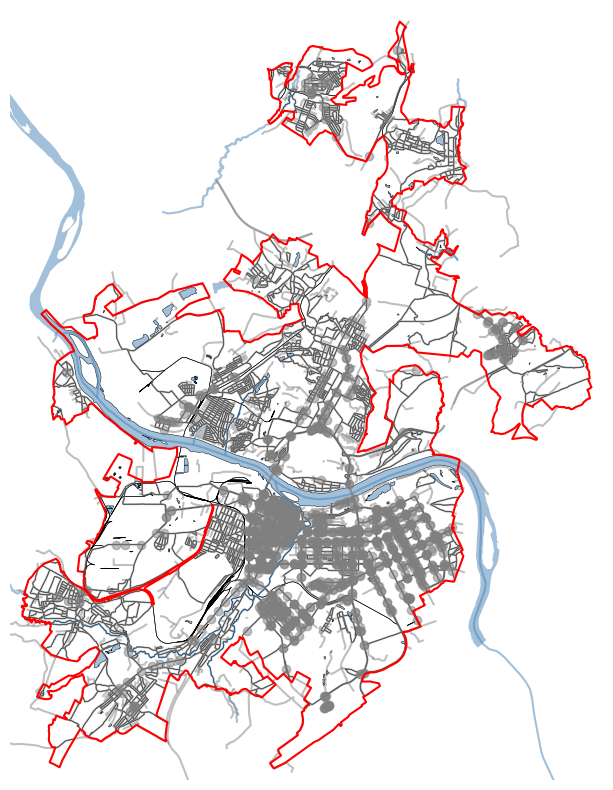

Кварталов: 2230 ; матрица времени будет иметь 4972900 значений


In [6]:
blocks_path = PROCESSED / 'blocks.geojson'
if blocks_path.exists() and not REFRESH:
    blocks = read_blocks(blocks_path, CRS)
else:
    roads = layers['roads'].loc[layers['roads'].geom_type.isin(['LineString','MultiLineString'])].copy()
    railways = layers['railways'].loc[layers['railways'].geom_type.isin(['LineString','MultiLineString'])].copy()
    water = layers['water'].loc[layers['water'].geom_type.isin(
        ['Polygon','MultiPolygon','LineString','MultiLineString'])].copy()
    assert len(roads), 'Нет линейных дорог: проверьте входные данные'
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundary, lines, polygons).reset_index(drop=True)
    blocks.index.name = 'block_id'
    assert len(blocks) and blocks.geometry.is_valid.all() and (blocks.area > 0).all()
    save_geo(blocks, blocks_path, 'block_id')
blocks['site_area'] = blocks.area
display(blocks[['site_area']].describe())
ax = blocks.plot(facecolor='none', edgecolor='black', linewidth=.4, figsize=(14,10))
for name, color in [('water','steelblue'),('roads','grey')]:
    if len(layers[name]): layers[name].plot(ax=ax, color=color, alpha=.5)
boundary.boundary.plot(ax=ax, color='red')
x0,y0,x1,y1 = boundary.total_bounds
ax.set_xlim(x0-500,x1+500); ax.set_ylim(y0-500,y1+500)
ax.set_axis_off(); plt.show()
display(blocks.to_crs(4326).explore(tooltip=['site_area']))
print('Кварталов:', len(blocks), '; матрица времени будет иметь', len(blocks)**2, 'значений')

# ОСТАНОВКА: проверьте кварталы до расчётов
Посмотрите центр, окраины, реку Томь, мосты и промышленные территории. Сохраните ноутбук.
Обсудите качество нарезки и задайте вопрос: «Какие метрики есть в BlocksNet и что означают
все показатели pipeline.ipynb для Кемерово?» После обсуждения измените флаг ниже.
Остальные ячейки защищены этим флагом; не запускайте их автоматически.

## Словарь результатов
| Группа | Показатели и смысл | Единицы |
|---|---|---|
| Землепользование | Доли каждой функции, преобладающая функция, её `share` | доля 0–1; категория |
| Транспорт | Время между каждой парой кварталов по готовому графу | минуты |
| Здания | `count`, `population`, `footprint_area`, `build_floor_area`, `living_area`, `non_living_area`, `number_of_floors`, `is_living` | объекты; оценка жителей; м²; суммы этажностей и числа жилых объектов |
| Школы | `count`, `capacity` и происхождение вместимости | объекты; места |
| Обеспеченность | `demand`, `capacity`, `demand_within`, `demand_without`, `demand_left`, `capacity_within`, `capacity_without`, `capacity_left`, `provision_strong`, `provision_weak`, связи `source,target,value` | места; доли |
| Плотность | `fsi` = площадь этажей / площадь квартала; `gsi` = пятно / площадь квартала | м²/м² |
| Смешанность | `mxi` = жилая площадь / площадь этажей | доля |
| Этажность | `l` = площадь этажей / пятно застройки | условные этажи |
| Открытые пространства | `osr` = (площадь квартала − пятно) / площадь этажей | м²/м² |
| Дополнительные отношения | `share_living`, `share_non_living` = жилая/нежилая площадь / пятно | м²/м², могут быть >1 |
| Морфотипы | Класс Spacematrix, номер кластера, медианы и интерпретации кластеров; класс «Стрелки» | категории; исходные единицы |
| Доступность по площади | `area_accessibility`: среднее время до кварталов с весами их площадей | минуты, меньше = ближе |

В агрегации примера `number_of_floors` суммируется, это **не средняя этажность**.
Отдельно ниже считается средняя этажность зданий. `is_living` после суммирования — число жилых объектов.
Восстановленное население не является официальной численностью жителей.
Для нулевого спроса обеспеченность не определена; для незастроенных кварталов часть отношений не определена.
При `max_depth=1`, как в примере, сильная и слабая обеспеченность могут совпадать:
слабая дополнительно учитывает распределение за пределами нормативного времени, которое требует большей глубины.

**Проверка агентом 30.10.2026:** получено 2230 кварталов; просмотрена карта границ, реки и дорожной нарезки. Исходные объекты реки выходят за город, но кварталы ограничены точной границей. В региональном PBF есть неполные ways за пределами города; аудит не нашёл неполных ways с доступным узлом внутри Кемерово (`raw/pbf_audit.json`). Полноту OSM как реального мира это не гарантирует. Продолжение расчётов разрешено пользователем.

In [7]:
CONTINUE_AFTER_BLOCKS = True  # Включите после обсуждения.
require_metrics()

## 5. Землепользование
Сопоставление тегов OSM повторяет правила примера. Неизвестные теги выводятся отдельно.
Доли могут суммироваться более чем в 1 при перекрывающихся полигонах OSM — это диагностируется,
а не исправляется скрытой нормализацией.

2026-10-30 02:33:17.037 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: basin, allotments, reservoir, quarry, greenhouse_horticulture, orchard, education, railway, meadow


Теги вне правил: ['allotments', 'basin', 'education', 'greenhouse_horticulture', 'meadow', 'orchard', 'quarry', 'railway', 'reservoir']


,residential,business,recreation,industrial,transport,special,agriculture,land_use,share,landuse_overlap_flag
0,0.671552,0.0,0.0,0.0,0.0,0.0,0.0,residential,0.671552,False
1,0.920731,0.0,0.0,0.0,0.0,0.0,0.0,residential,0.920731,False
2,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,None,NaN,False
3,0.880191,0.0,0.0,0.0,0.0,0.0,0.0,residential,0.880191,False
4,0.666282,0.0,0.0,0.0,0.0,0.0,0.0,residential,0.666282,False
...,...,...,...,...,...,...,...,...,...,...
2225,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,None,NaN,False
2226,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,None,NaN,False
2227,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,None,NaN,False
2228,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,None,NaN,False


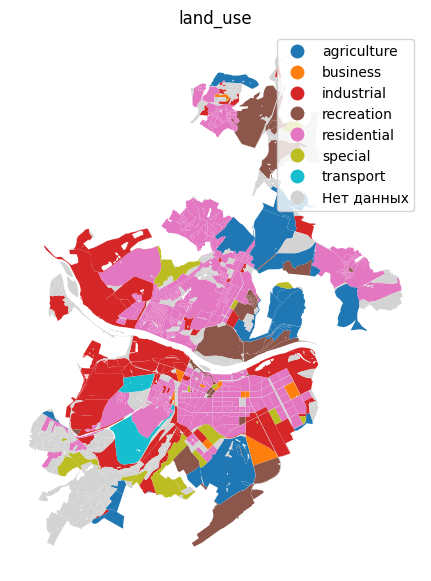

,count,mean,std,min,25%,50%,75%,max
residential,2230.0,0.246144,0.388287,0.000000e+00,0.000000,0.000000,0.713642,1.548283
business,2230.0,0.001561,0.026473,0.000000e+00,0.000000,0.000000,0.000000,0.821726
recreation,2230.0,0.023515,0.130289,0.000000e+00,0.000000,0.000000,0.000000,1.000000
industrial,2230.0,0.024171,0.129550,0.000000e+00,0.000000,0.000000,0.000000,1.000000
transport,2230.0,0.000092,0.003705,0.000000e+00,0.000000,0.000000,0.000000,0.171775
special,2230.0,0.003496,0.042516,0.000000e+00,0.000000,0.000000,0.000000,1.000000
agriculture,2230.0,0.008528,0.077809,0.000000e+00,0.000000,0.000000,0.000000,1.000000
share,980.0,0.690182,0.319786,8.975737e-15,0.488822,0.815876,0.927675,1.548283


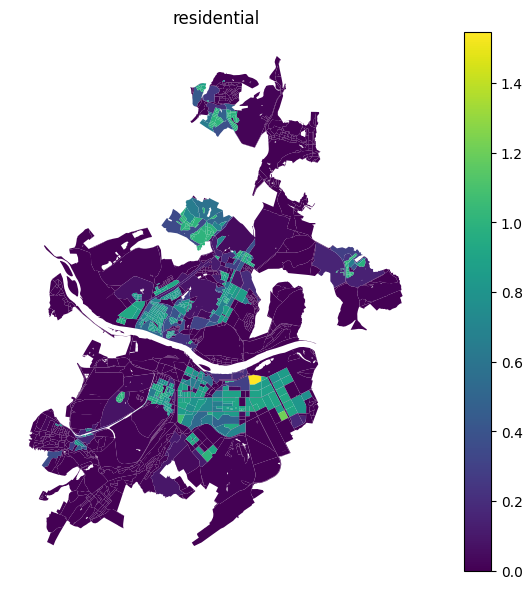

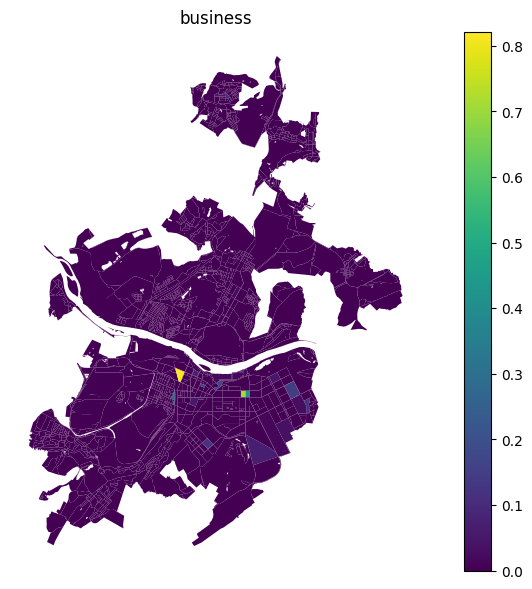

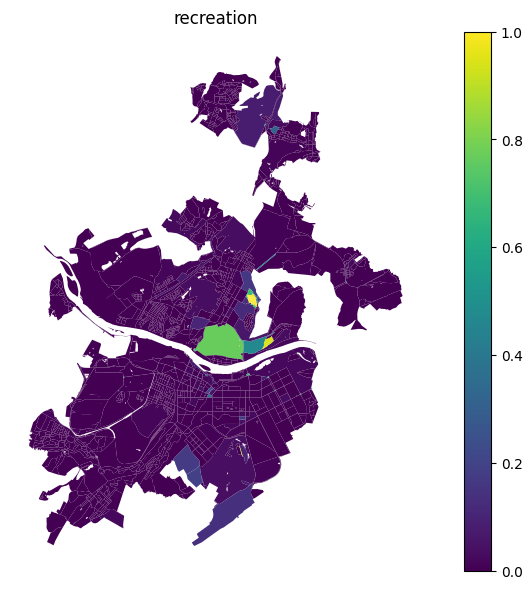

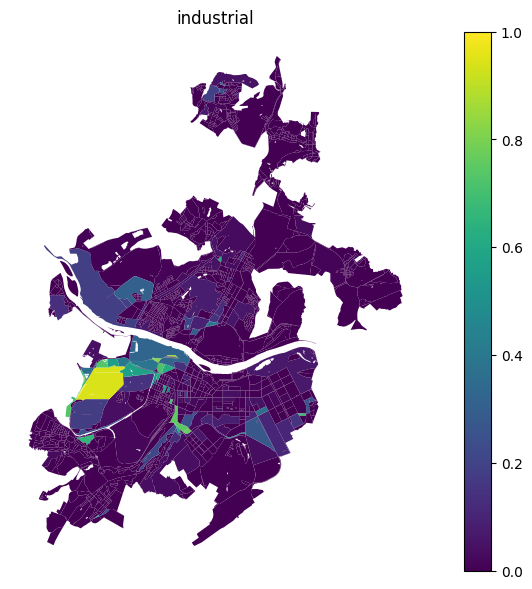

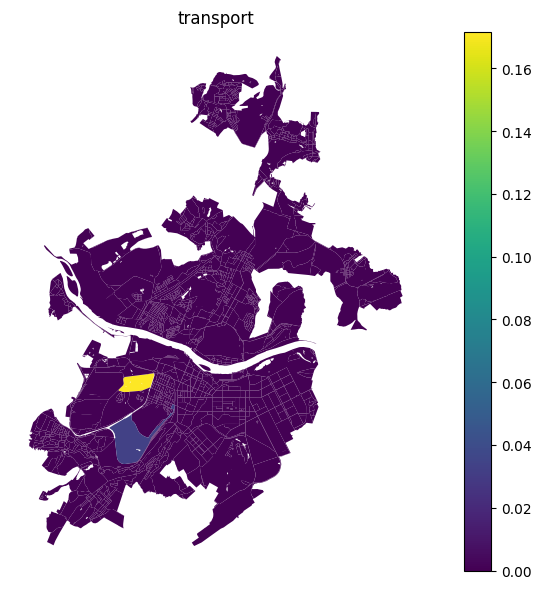

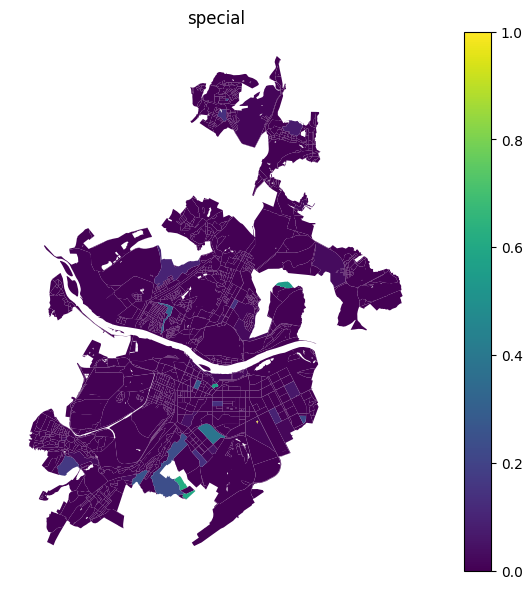

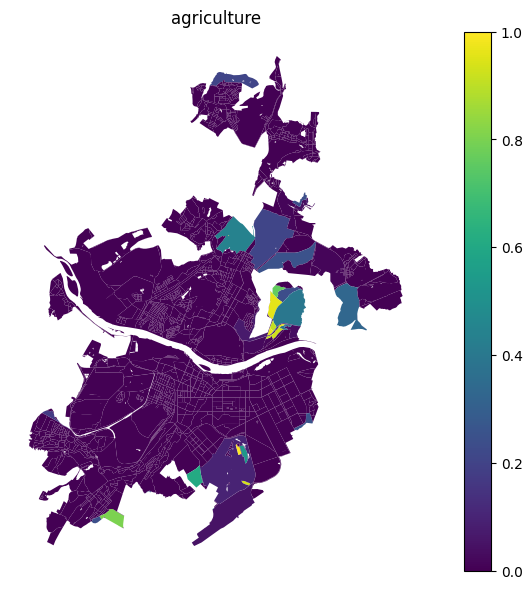

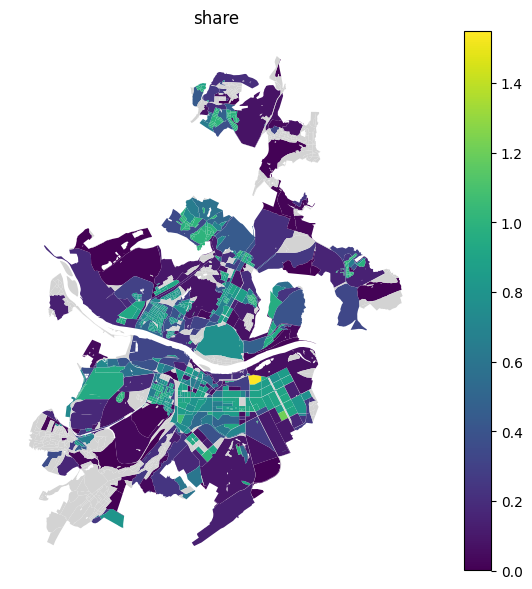

In [8]:
require_metrics()
rules = {key: getattr(LandUse, value) for key,value in {
 'commercial':'BUSINESS','industrial':'INDUSTRIAL','cemetery':'SPECIAL','garages':'INDUSTRIAL',
 'residential':'RESIDENTIAL','retail':'BUSINESS','grass':'RECREATION','farmland':'AGRICULTURE',
 'construction':'SPECIAL','brownfield':'INDUSTRIAL','forest':'RECREATION',
 'recreation_ground':'RECREATION','religious':'SPECIAL','flowerbed':'RECREATION',
 'military':'SPECIAL','landfill':'TRANSPORT'}.items()}
zones = clean_polygons(layers['functional_zones']).reset_index(drop=True)
assert 'landuse' in zones and len(zones), 'Нет полигонов землепользования'
zones = zones[['geometry','landuse']].rename(columns={'landuse':'functional_zone'})
print('Теги вне правил:', sorted(set(zones.functional_zone.dropna()) - set(rules)))
assert zones.functional_zone.isin(rules).any(), 'Нет функций, соответствующих правилам'
landuse = assign_land_use(blocks.copy(), zones.copy(), rules)
landuse['land_use'] = landuse.land_use.map(lambda x: x.value if isinstance(x, Enum) else x)
lu_columns = [x.value for x in LandUse]
landuse['landuse_overlap_flag'] = landuse[lu_columns].sum(axis=1) > 1.0001
display(landuse[lu_columns + ['land_use','share','landuse_overlap_flag']])
show_metric(landuse, 'land_use', categorical=True)
show_numeric(landuse, lu_columns + ['share'])
save_geo(landuse, RESULTS / 'landuse.geojson', 'block_id')

## 6. Автомобильный граф OSM — согласованное отступление
Пользователь 30.10.2026 разрешил построить автомобильный граф из OSM вместо скачивания
готового: официальный архив Harvard Dataverse `russia-RUS_graphml.zip`, file_id=10962604,
возвращает HTTP 403. Каталог получен через API экспорта и сохранён в raw/graph_catalog_export.json.

Используется только автомобильная сеть OSMnx, **не интермодальный граф**.
Скорости — оценки OSMnx по тегам maxspeed и типам дорог; отсутствующие восстанавливаются
по средним скоростям. Время = длина ребра / скорость. Это не фактический трафик.
Норматив школьной доступности из BlocksNet в автомобильном сценарии имеет только учебный смысл.


In [9]:
require_metrics()
print('Согласован автомобильный граф OSMnx вместо недоступного готового архива')

Согласован автомобильный граф OSMnx вместо недоступного готового архива


In [8]:
require_metrics()
GRAPH_PATH = RAW / 'kemerovo_drive.graphml'
GRAPH_SOURCE = 'OpenStreetMap contributors / OSMLab RU-KEM.pbf; local OSM ways; OSMnx drive filter'
GRAPH_DATE = json.loads((RAW / 'RU-KEM.metadata.json').read_text(encoding='utf-8')).get('last_modified', 'see PBF metadata')
GRAPH_MODE_CONFIRMED = True
GRAPH_COMPONENTS_CONFIRMED = True
GRAPH_COVERAGE_CONFIRMED = True
GRAPH_WEIGHT_ATTRIBUTE = 'travel_time'
GRAPH_WEIGHT_UNIT = 'seconds'


Узлов: 4889 Рёбер: 12314


,length,speed_kph,travel_time
count,12314.000000,12314.000000,12314.000000
mean,232.053360,52.922987,15.758254
std,413.353215,7.873716,23.385850
min,0.702821,20.000000,0.043045
25%,75.518425,51.428571,5.220676
50%,141.991745,51.428571,9.941618
75%,268.829750,51.428571,18.496380
max,17674.065315,110.000000,578.423956


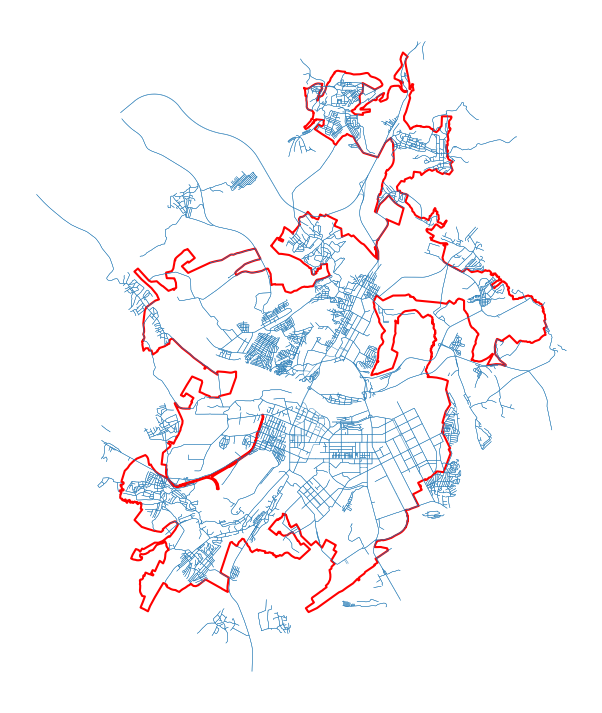

In [11]:
require_metrics()
if not GRAPH_PATH.exists() or REFRESH:
    drive_response = json.loads((RAW / 'drive_osm_response.json').read_text(encoding='utf-8'))
    graph = graph_from_response(drive_response)
    ox.save_graphml(graph, GRAPH_PATH)
    save_json({'source':GRAPH_SOURCE,'created_utc':datetime.now(timezone.utc).isoformat(),
       'mode':'drive','speeds':'OSM maxspeed / OSMnx imputation',
       'deviation':'User approved building a drive graph instead of a prebuilt download on 2026-10-30'},
       RAW / 'graph.metadata.json')
graph = ox.load_graphml(GRAPH_PATH)
nodes, edges = ox.graph_to_gdfs(graph)
print('Узлов:', len(nodes), 'Рёбер:',len(edges))
display(edges[['length','speed_kph','travel_time']].describe())
ax = boundary.boundary.plot(color='red',figsize=(12,9))
edges.to_crs(CRS).plot(ax=ax,linewidth=.3); ax.set_axis_off(); plt.show()


### Проверка покрытия и матрица времени
Подтвердите покрытие графом вручную, проверьте единицы веса по документации источника.
При отсутствии времён выполнение остановится: скорость не подставляется автоматически.
Проекция узлов меняется для совместимости с IduEdu. Отбор крупнейшей сильносвязной
компоненты требует отдельного подтверждения и проверки покрытия. Параллельные рёбра
сворачиваются с сохранением минимального времени, узлы перенумеровываются.
Время включает движение по сети между ближайшими узлами; внеуличные подходы не добавляются
(стандартная настройка IduEdu добавляет их со скоростью 5 км/ч).
Представительные точки кварталов привязываются к ближайшим узлам; расстояния привязки проверяются отдельно.
Матрица имеет n² ячеек, расчёт для всего города может быть длительным. Запускайте только вручную.
Ниже предусмотрен повторный запуск по сохранённой матрице без повторного расчёта.

**Проверка привязки:** из 2230 кварталов 26 находятся дальше 1 км от узла основной автомобильной сети; максимум 1976 м. Они показаны на диагностической карте (в основном периферийные/крупные участки с редкой публичной автомобильной сетью). После просмотра карты порог остановки повышен до 2 км; расстояние каждого квартала сохранено в `graph_attachment.geojson` и итоговом наборе. Внеуличное время не включено, поэтому доступность этих кварталов оптимистична. Не интерпретируйте её как время от каждой двери.

In [9]:
# Измените после проверки карты и метаданных; не подтверждайте вслепую.
GRAPH_COVERAGE_CONFIRMED = True
MAX_SNAP_METERS = 2000  # Порог диагностики, не норматив; большие расстояния требуют проверки.
REUSE_MATRIX = True

Недостижимых/отсутствующих пар: 0


block_id,0,1,2,3,4,5,6,7,8,9,...,2220,2221,2222,2223,2224,2225,2226,2227,2228,2229
block_id,,,,,,,,,,,,,,,,,,,,,
0,0.00,0.24,0.21,0.49,0.29,0.29,3.00,3.23,3.36,3.82,...,1.46,11.71,2.86,19.120001,13.97,12.23,12.80,12.22,4.71,17.510000
1,0.24,0.00,0.40,0.44,0.53,0.32,3.24,3.47,3.60,4.06,...,1.47,11.77,3.10,19.180000,14.21,12.47,12.86,12.28,4.77,17.570000
2,0.21,0.40,0.00,0.28,0.24,0.08,2.94,3.17,3.30,3.76,...,1.67,11.92,2.80,19.330000,13.91,12.17,13.01,12.43,4.92,17.719999
3,0.49,0.44,0.28,0.00,0.52,0.20,3.20,3.43,3.56,4.02,...,1.91,12.20,3.06,19.610001,14.17,12.43,13.29,12.71,5.20,18.000000
4,0.29,0.53,0.24,0.52,0.00,0.32,2.71,2.94,3.07,3.53,...,1.75,12.00,2.57,19.410000,13.68,11.94,13.09,12.51,5.00,17.799999


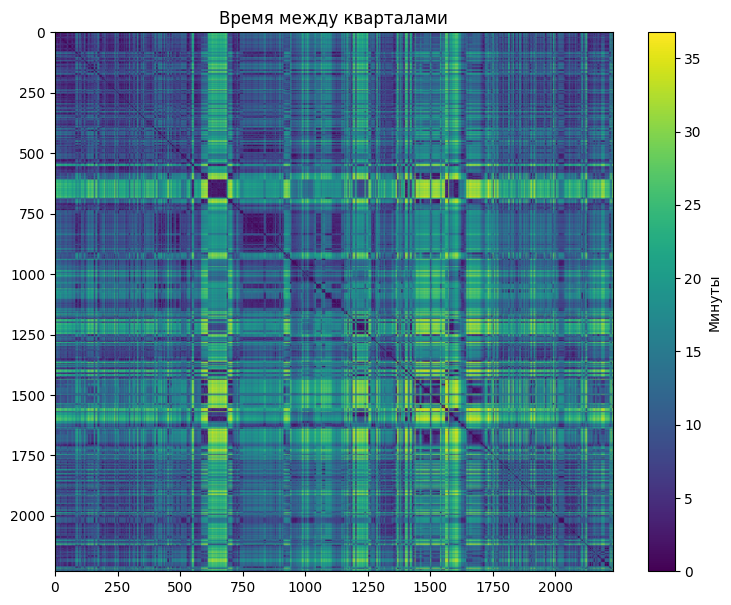

GeoJSON матрицы прочитан; значения совпадают с Parquet с точностью 0.01 минуты


In [10]:
require_metrics()
matrix_path = RESULTS / 'travel_time.parquet'
matrix_meta_path = RESULTS / 'travel_time.metadata.json'
blocks_hash = hashlib.sha256(b''.join(blocks.geometry.to_wkb())).hexdigest()
graph_hash = hashlib.sha256(GRAPH_PATH.read_bytes()).hexdigest()
signature = {'blocks_hash':blocks_hash,'graph_hash':graph_hash,
             'weight':GRAPH_WEIGHT_ATTRIBUTE,'unit':GRAPH_WEIGHT_UNIT,
             'largest_scc':GRAPH_COMPONENTS_CONFIRMED,'off_network_access':False}
if REUSE_MATRIX and matrix_path.exists():
    matrix_meta = json.loads(matrix_meta_path.read_text(encoding='utf-8'))
    assert matrix_meta['signature'] == signature, 'Матрица относится к другим входным данным'
    acc_mx = pd.read_parquet(matrix_path)
    graph_attachment = read_blocks(RESULTS / 'graph_attachment.geojson', CRS)
    acc_mx.index = acc_mx.index.astype(int); acc_mx.columns = acc_mx.columns.astype(int)
else:
    assert GRAPH_COVERAGE_CONFIRMED and GRAPH_MODE_CONFIRMED
    graph = ox.load_graphml(GRAPH_PATH)  # Начинаем с неизменённого исходного файла.
    assert GRAPH_WEIGHT_UNIT in ['seconds','minutes']
    factor = 1/60 if GRAPH_WEIGHT_UNIT == 'seconds' else 1
    for _,_,d in graph.edges(data=True):
        if GRAPH_WEIGHT_ATTRIBUTE not in d: raise ValueError('В графе отсутствует подтверждённое время ребра')
        d['time_min'] = float(d[GRAPH_WEIGHT_ATTRIBUTE]) * factor
        assert np.isfinite(d['time_min']) and d['time_min'] >= 0
    graph = ox.project_graph(graph, to_crs=CRS)
    assert graph.is_directed(), 'Для этого сценария требуется направленный автомобильный граф'
    # IduEdu a9 оставляет крупнейшую сильносвязную компоненту: делаем этот выбор явно.
    components = sorted(nx.strongly_connected_components(graph), key=len, reverse=True)
    print('Размеры сильносвязных компонент:', [len(c) for c in components[:20]])
    if len(components) > 1:
        assert GRAPH_COMPONENTS_CONFIRMED, 'Подтвердите отбор компоненты после проверки покрытия'
        graph = graph.subgraph(components[0]).copy()
    # IduEdu сворачивает параллельные рёбра; заранее сохраняем минимальное время.
    if graph.is_multigraph():
        graph = ox.convert.to_digraph(graph, weight='time_min')
    # IduEdu использует номера узлов как позиции CSR: нужны последовательные целые номера.
    graph = nx.convert_node_labels_to_integers(graph, ordering='default', label_attribute='source_node_id')
    graph.graph['crs'] = int(CRS.to_epsg())
    validate_accessibility_graph(graph)
    points = blocks.representative_point()
    snap_node_ids, snap_dist = ox.distance.nearest_nodes(graph, points.x.to_numpy(), points.y.to_numpy(), return_dist=True)
    display(pd.Series(snap_dist, index=blocks.index, name='snap_distance_m').describe())
    graph_attachment = blocks[['geometry']].copy()
    graph_attachment['snap_distance_m'] = np.asarray(snap_dist)
    graph_attachment['snap_node_id'] = np.asarray(snap_node_ids)
    graph_attachment['far_snap_over_1000m'] = np.asarray(snap_dist) > 1000
    save_geo(graph_attachment, RESULTS / 'graph_attachment.geojson', 'block_id')
    assert np.max(snap_dist) <= MAX_SNAP_METERS, 'Плохое покрытие графом: проверьте дальние привязки'
    acc_mx = calculate_accessibility_matrix(blocks.copy(), graph, dtype=np.float32,
                                            add_dist_tofrom_node=False, max_workers=2)
    acc_mx.index = blocks.index; acc_mx.columns = blocks.index
    acc_mx.to_parquet(matrix_path)
    save_json({'signature':signature,'source':GRAPH_SOURCE,'snapshot_date':GRAPH_DATE,
               'mode':'drive','unit':'minutes'}, matrix_meta_path)
assert acc_mx.index.equals(blocks.index) and acc_mx.columns.equals(blocks.index)
assert (acc_mx.to_numpy()[np.isfinite(acc_mx.to_numpy())] >= 0).all()
assert np.allclose(np.diag(acc_mx), 0), 'Проверьте диагональ матрицы'
print('Недостижимых/отсутствующих пар:', (~np.isfinite(acc_mx.to_numpy())).sum())
display(acc_mx.head())
plt.figure(figsize=(9,7)); plt.imshow(acc_mx.replace([np.inf,-np.inf],np.nan), aspect='auto')
plt.colorbar(label='Минуты'); plt.title('Время между кварталами'); plt.show()
# Один объект-точка на исходный квартал; массив target_block_ids общий для коллекции.
# native JSON arrays сохраняют матрицу без n² повторов геометрии и целевых id.
from shapely.geometry import mapping
points_wgs84 = blocks.representative_point().to_crs(4326)
features = []
for source_id, row in acc_mx.iterrows():
    features.append({'type':'Feature','geometry':mapping(points_wgs84.loc[source_id]),
        'properties':{'source_block_id':int(source_id),
                      'time_min':[round(float(v),2) if np.isfinite(v) else None for v in row]}})
geo_matrix = {'type':'FeatureCollection','target_block_ids':list(map(int,acc_mx.columns)),
              'time_unit':'minutes','rounding_minutes':.01,'features':features}
geo_matrix_path = RESULTS / 'travel_time_rows.geojson'
geo_matrix_path.write_text(json.dumps(geo_matrix,ensure_ascii=False,separators=(',',':'),allow_nan=False),encoding='utf-8')
restored_geo = json.loads(geo_matrix_path.read_text(encoding='utf-8'))
assert restored_geo['target_block_ids'] == list(acc_mx.columns)
assert [f['properties']['source_block_id'] for f in restored_geo['features']] == list(acc_mx.index)
geo_values = np.array([f['properties']['time_min'] for f in restored_geo['features']],dtype=float)
np.testing.assert_allclose(geo_values,acc_mx.to_numpy(),atol=.005001,rtol=0)
print('GeoJSON матрицы прочитан; значения совпадают с Parquet с точностью 0.01 минуты')


## 7. Здания и модельная оценка населения
Как в примере: жилые типы — residential, house, apartments, detached, terrace, dormitory.
Этажность берётся из `building:levels`; отсутствующая заменяется 1 этажом.
Пятно = площадь полигона, площадь этажей = пятно × этажность, жилая площадь = 0.9 площади этажей
жилого здания, оценка населения = жилая площадь / 30 м² на человека (округление BlocksNet).
Это допущения учебного примера, они могут существенно занижать население и этажность.
Сохраняются признаки оценённых значений и исключённые объекты.
Точки-здания не превращаются в полигоны и учитываются в отчёте качества.

### Корректировка общего населения
Пользователь указал численность Кемерово **542 928 человек**. Год статистики и внешний
источник не указаны, поэтому это контрольная численность пользователя, без приписывания
её конкретной переписи или году. Первичная оценка 158 384 сохраняется для сравнения.
По кварталам 542 928 жителей распределяются пропорционально первичной оценке населения,
методом наибольших остатков: целые числа, точная сумма, стабильное разрешение равных остатков
по порядку block_id. Это не наблюдаемые данные населения отдельных кварталов.
Пересчитываются спрос и обеспеченность школами; вместимость школ не корректируется под спрос.


2026-10-30 02:54:35.425 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None


2026-10-30 02:54:35.426 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None


2026-10-30 02:54:35.427 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None


2026-10-30 02:54:35.427 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None


2026-10-30 02:54:35.427 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


2026-10-30 02:54:35.537 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-30 02:54:35.552 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


raw_objects         38020
polygon_parts       38016
outside_blocks          4
floors_estimated    36402
dtype: int64

,count,mean,std,min,25%,50%,75%,max
population,2230.0,243.465471,2056.906072,0.0,0.0,0.000000,0.000000,59762.000000
footprint_area,2230.0,6016.751044,21023.937938,0.0,0.0,772.796617,2927.676175,358946.951401
number_of_floors,2230.0,19.888789,58.286634,0.0,0.0,5.000000,19.000000,1469.000000
build_floor_area,2230.0,9233.923711,35101.853331,0.0,0.0,776.092529,2983.023292,786323.839687
is_living,2230.0,1.003139,5.266474,0.0,0.0,0.000000,0.000000,94.000000
living_area,2230.0,2145.768031,18038.610369,0.0,0.0,0.000000,0.000000,523772.295264
non_living_area,2230.0,7088.155680,24367.209555,0.0,0.0,671.812970,2782.301700,375626.641498
floors_estimated,2230.0,16.321973,51.786283,0.0,0.0,4.000000,17.000000,1463.000000
population_estimated,2230.0,1.003139,5.266474,0.0,0.0,0.000000,0.000000,94.000000
area_estimated,2230.0,17.045740,52.837933,0.0,0.0,5.000000,18.000000,1469.000000


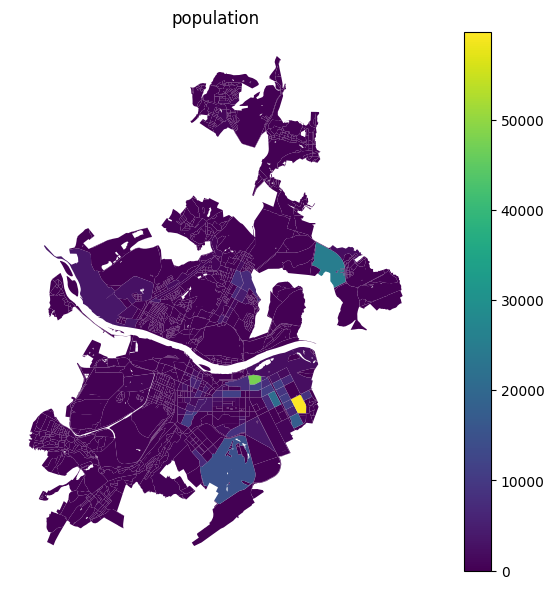

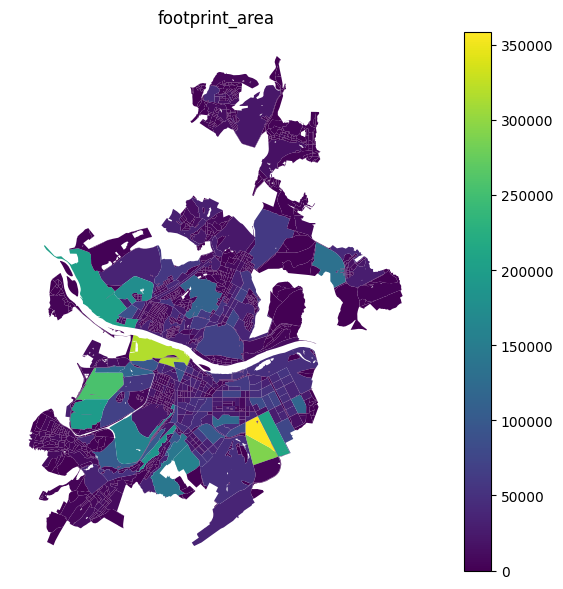

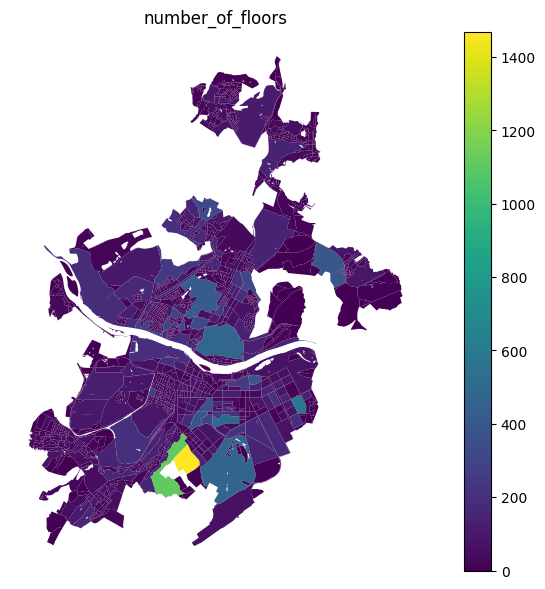

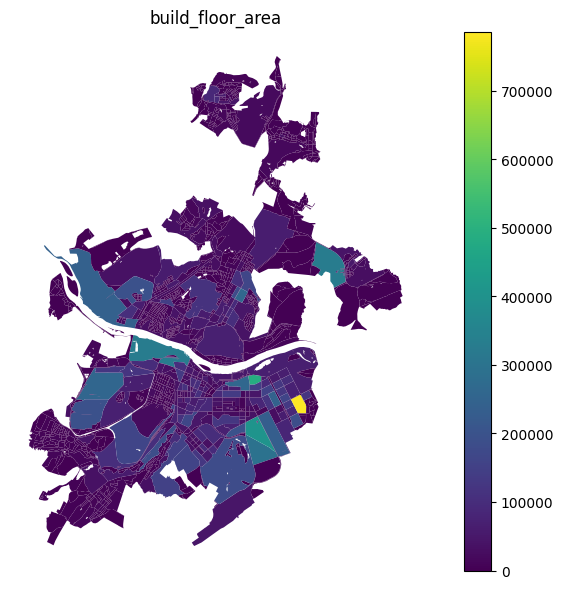

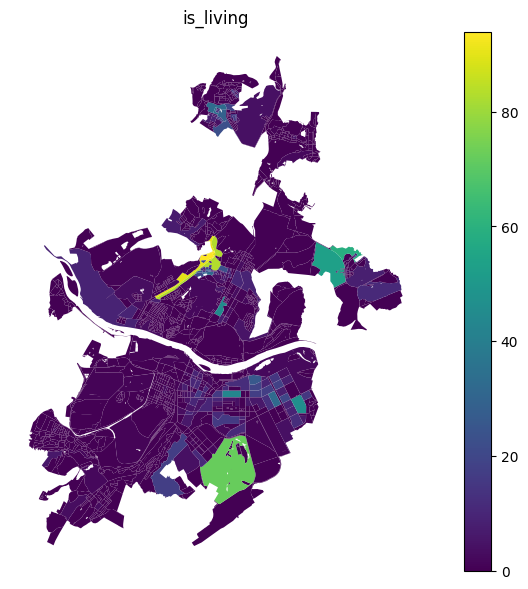

...

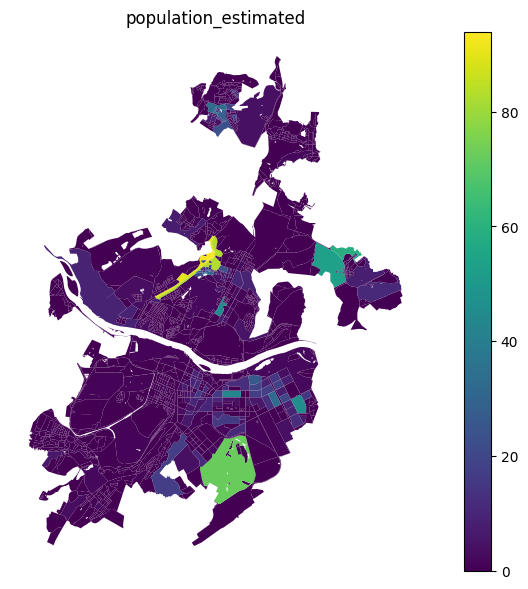

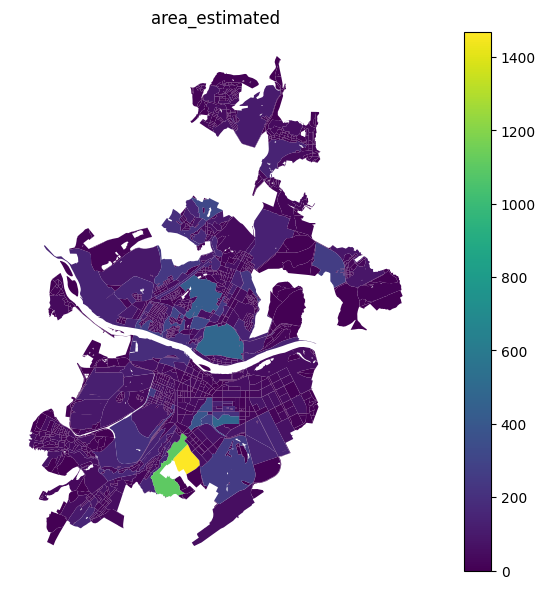

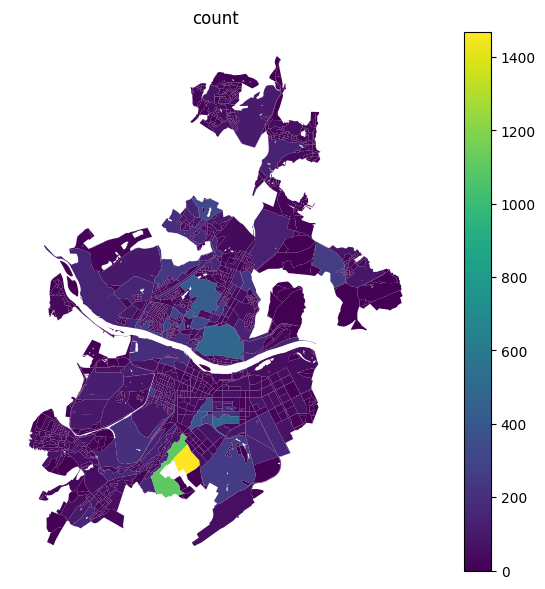

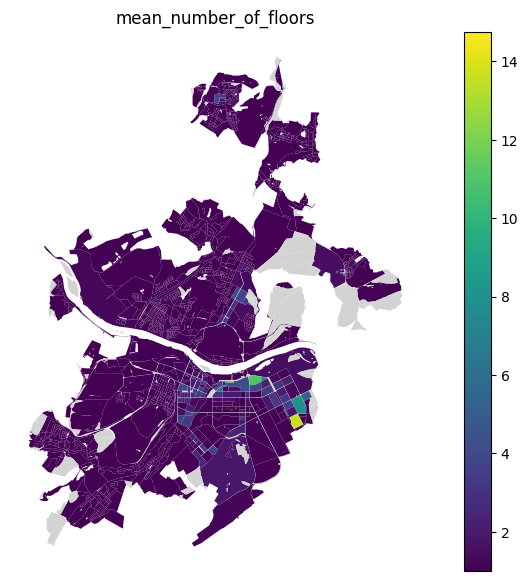

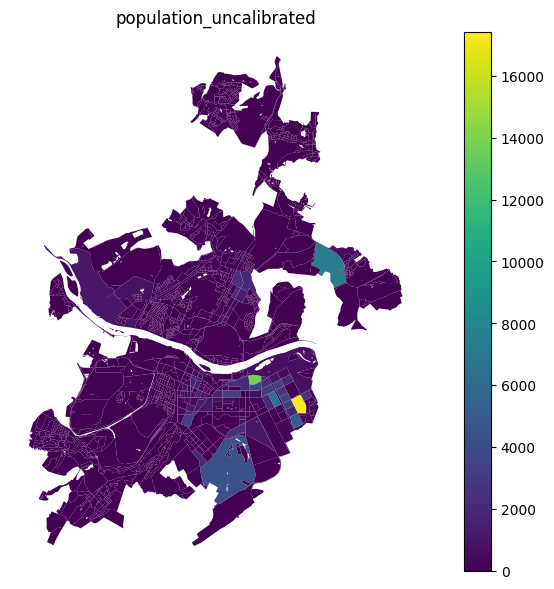

In [11]:
require_metrics()
raw_buildings = layers['buildings'].copy()
buildings = clean_polygons(raw_buildings)
buildings = buildings.reset_index(drop=True)
assert len(buildings), 'Нет полигонов зданий'
buildings['is_living'] = buildings['building'].isin(['residential','house','apartments','detached','terrace','dormitory'])
buildings['number_of_floors'] = pd.to_numeric(buildings.get('building:levels', pd.Series(np.nan,index=buildings.index)), errors='coerce')
buildings.loc[buildings.number_of_floors <= 0,'number_of_floors'] = np.nan
buildings['floors_estimated'] = buildings.number_of_floors.isna().astype(int)
buildings['population_estimated'] = buildings.is_living.astype(int)
buildings['area_estimated'] = 1
building_provenance = buildings[['floors_estimated','population_estimated','area_estimated']].copy()
buildings = impute_buildings(buildings, default_number_of_floors=1,
                             living_area_coefficient=.9, default_living_demand=30)
buildings = buildings.join(building_provenance)
# Агрегируем только поля модели, чтобы OSM id и другие числовые теги не суммировались.
building_fields = ['population','footprint_area','number_of_floors','build_floor_area',
                   'is_living','living_area','non_living_area','floors_estimated','population_estimated','area_estimated']
buildings_blocks, excess_buildings = aggregate_objects(blocks[['geometry']].copy(), buildings[['geometry']+building_fields].copy())
# Сохраняем исходные веса, а калибровку выполняем по агрегированным кварталам.
buildings_blocks['population_uncalibrated'] = buildings_blocks['population'].copy()
weights = buildings_blocks.population_uncalibrated.astype(float)
assert weights.sum() > 0 and (weights >= 0).all()
quotas = weights.to_numpy() / weights.sum() * POPULATION_TOTAL
allocated = np.floor(quotas).astype(np.int64)
remaining = int(POPULATION_TOTAL - allocated.sum())
order = np.argsort(-(quotas - allocated), kind='stable')
allocated[order[:remaining]] += 1
buildings_blocks['population'] = allocated
assert int(buildings_blocks.population.sum()) == POPULATION_TOTAL
assert (buildings_blocks.loc[weights == 0,'population'] == 0).all()
save_json({'target_total':POPULATION_TOTAL,'source':POPULATION_SOURCE,
    'uncalibrated_total':float(weights.sum()),'factor':float(POPULATION_TOTAL/weights.sum()),
    'method':'Block-level proportional allocation with largest remainders; original OSM model weights',
    'block_population_is_estimated':True},RESULTS / 'population_calibration.json')
buildings_blocks['site_area'] = blocks.area
buildings_blocks['mean_number_of_floors'] = buildings_blocks.number_of_floors / buildings_blocks['count'].replace(0,np.nan)
display(pd.Series({'raw_objects':len(raw_buildings),'polygon_parts':len(buildings),
                   'outside_blocks':len(excess_buildings),'floors_estimated':int(buildings.floors_estimated.sum())}))
show_numeric(buildings_blocks, building_fields + ['count','mean_number_of_floors','population_uncalibrated'])
save_geo(buildings, PROCESSED / 'buildings_model.geojson')
save_geo(buildings_blocks, RESULTS / 'buildings.geojson','block_id')
save_geo(excess_buildings, PROCESSED / 'buildings_outside_blocks.geojson')

## 8. Школы: количество и вместимость
Школьный кампус и его здания могут дублироваться в OSM. Вложенные точки/полигоны
объединяются с покрывающим школьным полигоном; список исключённых записей сохраняется.
Это геометрическая эвристика: проверьте карту и названия, в одном кампусе могут быть разные школы.
Вместимость берётся только из числового `capacity`; отсутствующая — минимальная вместимость
из конфигурации BlocksNet, как в примере. Отдельно сохраняются исходные и оценённые места.
Нулевая исходная вместимость не заменяется автоматически.

2026-10-30 02:33:50.785 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-30 02:33:50.786 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


,capacity,capacity_estimated,capacity_observed_places,capacity_estimated_places
0,250.0,1,0.0,250.0
1,250.0,1,0.0,250.0
3,250.0,1,0.0,250.0
4,250.0,1,0.0,250.0
5,250.0,1,0.0,250.0
...,...,...,...,...
108,250.0,1,0.0,250.0
109,250.0,1,0.0,250.0
110,250.0,1,0.0,250.0
111,250.0,1,0.0,250.0


,count,mean,std,min,25%,50%,75%,max
count,2230.0,0.050224,0.289160,0.0,0.0,0.0,0.0,4.0
capacity,2230.0,12.556054,72.290074,0.0,0.0,0.0,0.0,1000.0
capacity_estimated,2230.0,0.050224,0.289160,0.0,0.0,0.0,0.0,4.0
capacity_observed_places,2230.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
capacity_estimated_places,2230.0,12.556054,72.290074,0.0,0.0,0.0,0.0,1000.0


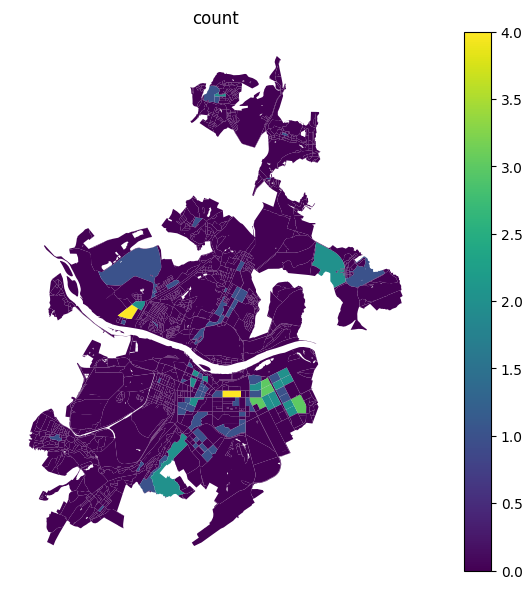

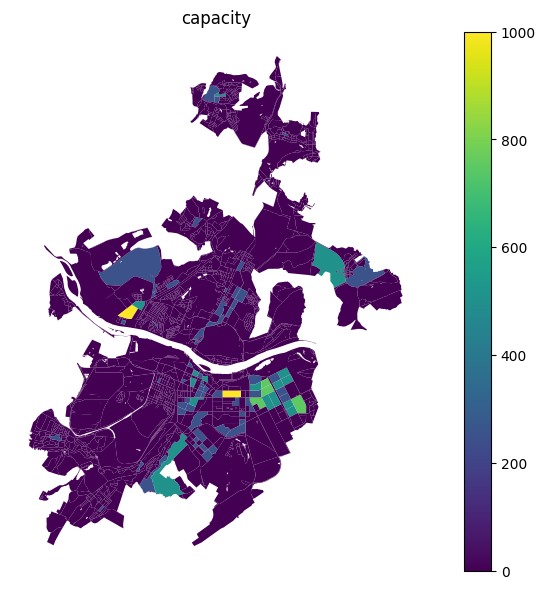

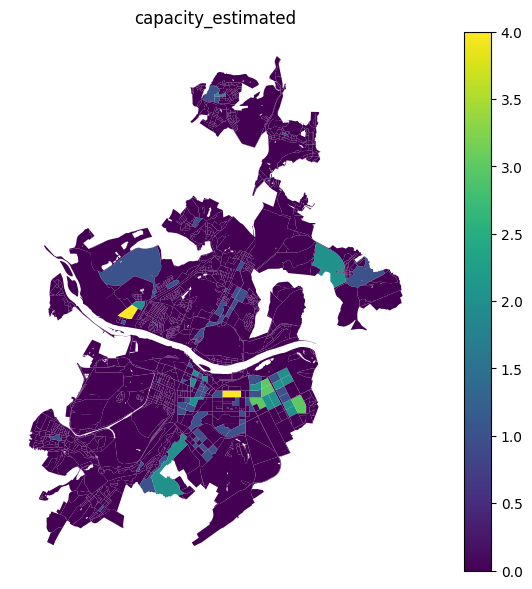

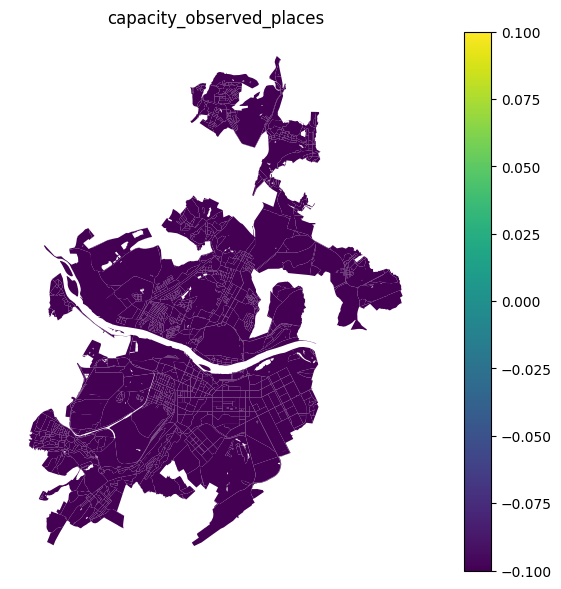

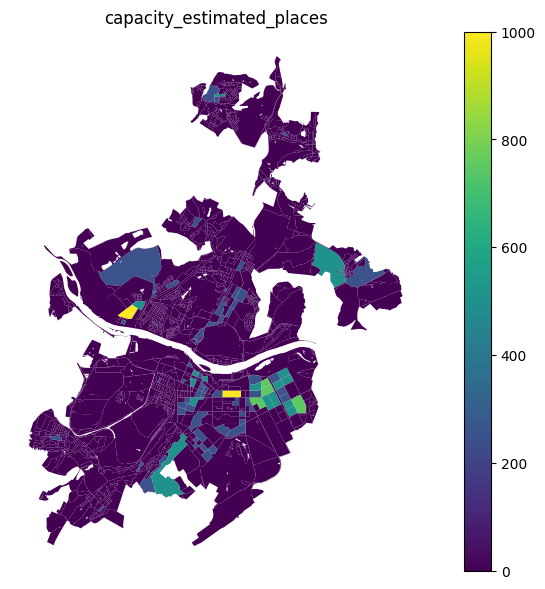

In [15]:
require_metrics()
schools = layers['schools'].copy().reset_index(drop=True)
assert len(schools), 'Нет школ в OSM: нельзя завершить обеспеченность без проверки данных'
schools = schools.loc[schools.geometry.notna() & ~schools.geometry.is_empty].copy()
polys = schools[schools.geom_type.isin(['Polygon','MultiPolygon'])].copy()
drop_ids = []
for idx, row in schools.iterrows():
    for other, campus in polys.iterrows():
        if idx != other and campus.geometry.covers(row.geometry) and (
                campus.geometry.area > row.geometry.area or other < idx):
            drop_ids.append(idx); break
duplicates = schools.loc[drop_ids].copy()
schools = schools.drop(index=drop_ids).copy()
schools['capacity'] = pd.to_numeric(schools.get('capacity',pd.Series(np.nan,index=schools.index)), errors='coerce')
schools.loc[schools.capacity < 0,'capacity'] = np.nan
schools['capacity_estimated'] = schools.capacity.isna().astype(int)
schools['capacity_observed_places'] = schools.capacity.fillna(0)
school_provenance = schools[['capacity_estimated','capacity_observed_places']].copy()
schools = impute_services(schools,'school').join(school_provenance)
schools['capacity_estimated_places'] = schools.capacity * schools.capacity_estimated
school_fields = ['capacity','capacity_estimated','capacity_observed_places','capacity_estimated_places']
schools_blocks, excess_schools = aggregate_objects(blocks[['geometry']].copy(), schools[['geometry']+school_fields].copy())
display(schools.drop(columns='geometry'))
show_numeric(schools_blocks, ['count']+school_fields)
display(schools.to_crs(4326).explore(tooltip=['capacity','capacity_estimated']))
save_geo(schools, PROCESSED / 'schools_model.geojson')
save_geo(duplicates, PROCESSED / 'school_duplicates_review.geojson')
save_geo(excess_schools, PROCESSED / 'schools_outside_blocks.geojson')
save_geo(schools_blocks, RESULTS / 'schools.geojson','block_id')

## 9. Конкурентная обеспеченность школами
Нормативный спрос и время берутся из конфигурации версии a9 по именованным полям.
Спрос округляется вверх на каждый квартал. Модель распределяет места с учётом конкуренции.
`strong` — удовлетворённый спрос в пределах нормативного времени; `weak` дополнительно
учитывает места за его пределами. `demand_left` — неудовлетворённый спрос,
`capacity_left` — свободные места. `within/without` разделяют распределение по времени.
Как в примере, глубина = 1, поэтому внешнее распределение может быть нулевым.
Недостижимые пары не заменяются нулём. При нулевом спросе доля остаётся пустой.
Линии спроса соединяют кварталы схематично, не показывают маршрут по улицам.

2026-10-30 02:56:11.236 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame


2026-10-30 02:56:11.237 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter


2026-10-30 02:56:11.249 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-10-30 02:56:11.270 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


{'name_ru': 'школа', 'demand': 120, 'accessibility': 15}


2026-10-30 02:56:11.839 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


,count,mean,std,min,25%,50%,75%,max
demand,2230.0,29.268161,246.876394,0.0,0.0,0.0,0.0,7172.0
capacity,2230.0,12.556054,72.290074,0.0,0.0,0.0,0.0,1000.0
demand_left,2230.0,16.712108,117.823242,0.0,0.0,0.0,0.0,2122.0
demand_within,2230.0,12.556054,180.169942,0.0,0.0,0.0,0.0,5696.0
demand_without,2230.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
capacity_left,2230.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
capacity_within,2230.0,5.979821,44.075082,0.0,0.0,0.0,0.0,819.0
capacity_without,2230.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
provision_strong,237.0,0.183818,0.354047,0.0,0.0,0.0,0.0,1.0
provision_weak,237.0,0.183818,0.354047,0.0,0.0,0.0,0.0,1.0


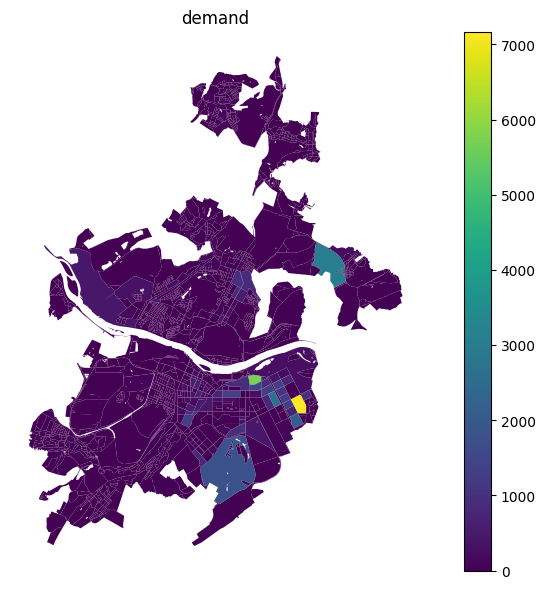

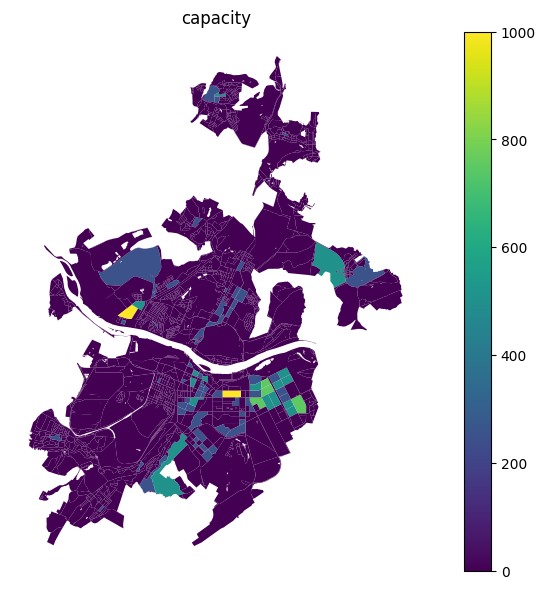

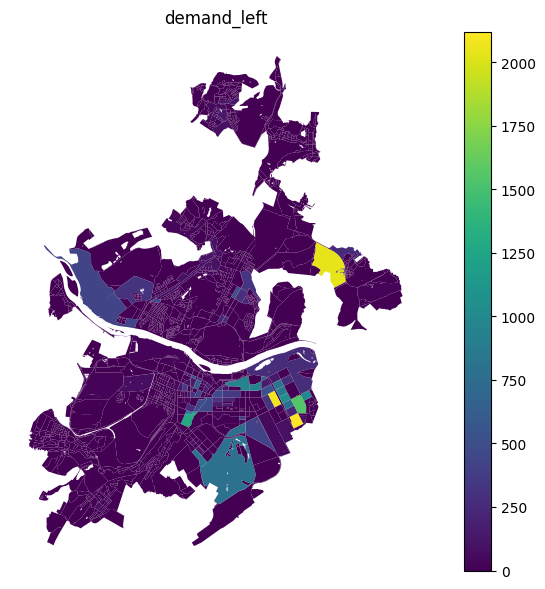

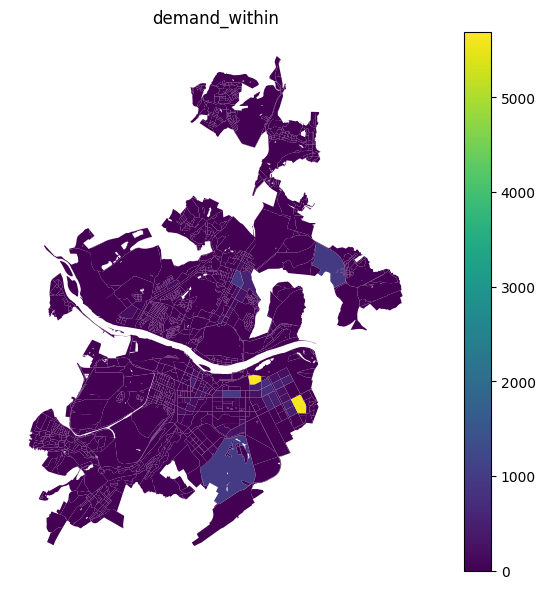

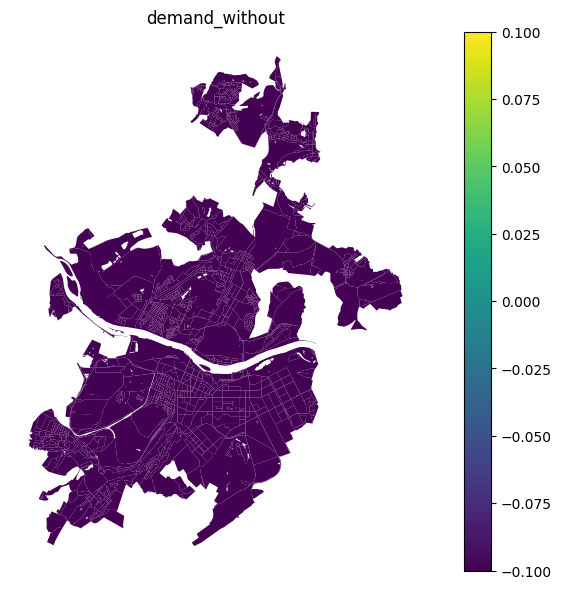

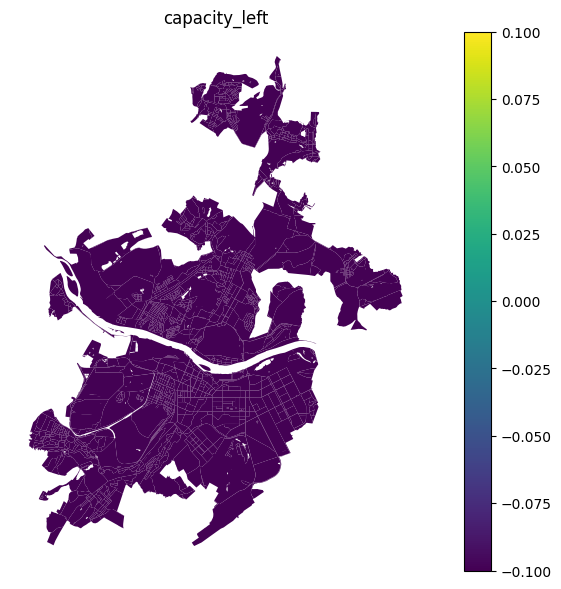

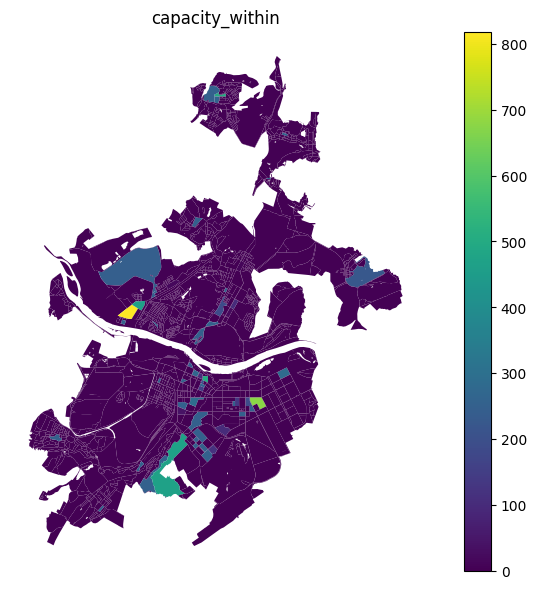

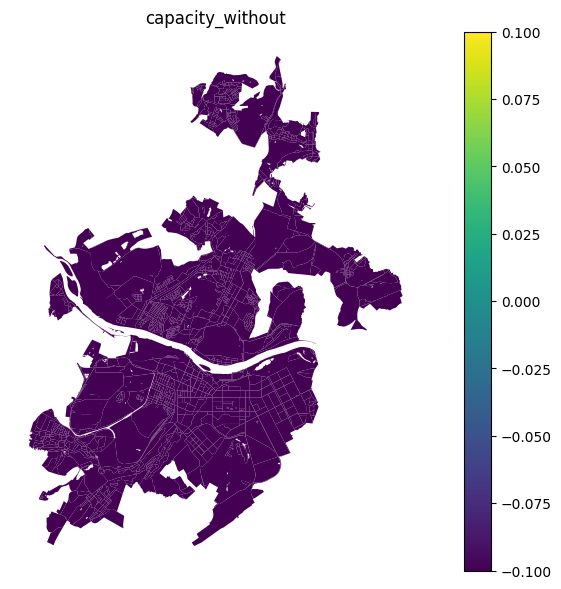

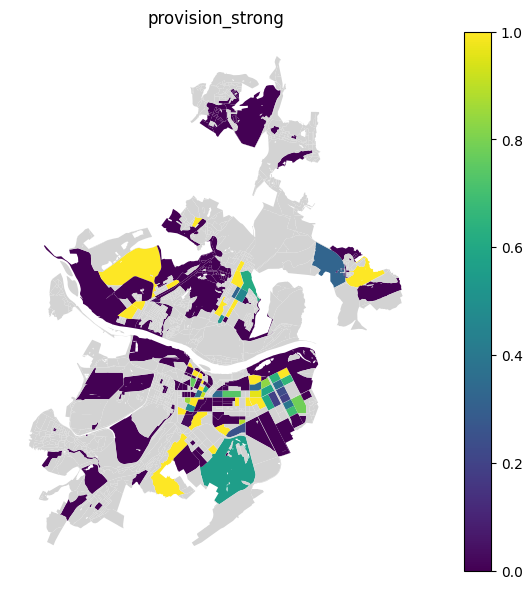

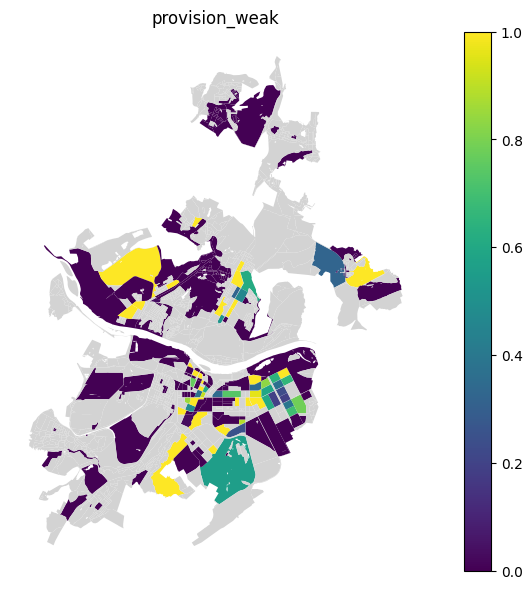

value
source target       
93     1824     41.0
171    416      17.0
241    330      15.0
       648     250.0
       1566    250.0
937    320     250.0
       704     250.0
       1314    250.0
       1476    250.0
1274   330     229.0
       634     500.0
       1241    250.0
1295   1039    223.0
       1615    250.0
1332   67      500.0
       90      250.0
       195     678.0
       218     250.0
       227     208.0
       233     250.0
       234     150.0
       285     250.0
       288     250.0
       310     131.0
       386     226.0
       399     819.0
       401     462.0
       433     250.0
       499       5.0
       569     268.0
       686     249.0
       951     250.0
1879   23      101.0
       131     250.0
       134     250.0
       137      97.0
       156     188.0
       209      21.0
       211     468.0
       214     290.0
       247     249.0
       255     250.0
       315      11.0
       322     250.0
       371     250.0
       379     250.0
       384     250.0
       430     250.0
       499     281.0
       769     250.0
       1184    250.0
       1316    121.0
       1571    101.0
       1782    186.0
       1796    250.0

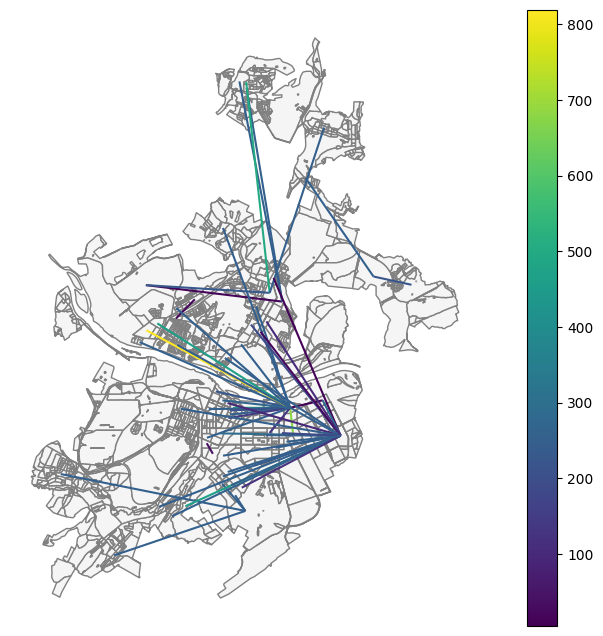

In [11]:
require_metrics()
if 'buildings_blocks' not in globals(): buildings_blocks = read_blocks(RESULTS / 'buildings.geojson', CRS)
if 'schools_blocks' not in globals(): schools_blocks = read_blocks(RESULTS / 'schools.geojson', CRS)
school_config = service_types_config['school']
print(school_config)
assert 'demand' in school_config and 'accessibility' in school_config
norm_demand = int(school_config['demand'])
norm_accessibility = int(school_config['accessibility'])
assert not acc_mx.isna().any().any(), 'В матрице есть NaN: сначала выясните причину'
provision_input = buildings_blocks[['population']].join(schools_blocks[['capacity']])
prov_df, links_df = competitive_provision(provision_input, acc_mx, norm_accessibility,
                                         norm_demand, max_depth=1)
prov_df.loc[prov_df.demand == 0,['provision_strong','provision_weak']] = np.nan
assert np.allclose(prov_df.demand,prov_df.demand_within + prov_df.demand_without + prov_df.demand_left)
assert np.isclose(prov_df.capacity.sum(),prov_df.demand_within.sum()+prov_df.demand_without.sum()+prov_df.capacity_left.sum())
provision = blocks[['geometry']].join(prov_df)
show_numeric(provision, list(prov_df.columns))
display(links_df)
links_table = links_df.reset_index()
points = blocks.representative_point()
links_geo = gpd.GeoDataFrame(links_table, geometry=[LineString([points.loc[s],points.loc[t]])
    for s,t in zip(links_table.source,links_table.target)], crs=CRS)
save_geo(provision, RESULTS / 'provision.geojson','block_id')
save_geo(links_geo, RESULTS / 'school_demand_links.geojson')
links_table.to_csv(RESULTS / 'school_demand_links.csv',index=False)
if len(links_geo):
    ax = blocks.plot(color='whitesmoke', edgecolor='grey',figsize=(12,8))
    links_geo.plot(ax=ax,column='value',legend=True); ax.set_axis_off(); plt.show()
else: print('Межквартальных связей нет: проверьте спрос, вместимость и покрытие графом.')

## 10. Плотность и типы застройки
Рассчитываются все семь показателей плотности из a9. Бесконечные отношения при нулевом
знаменателе сохраняются как отсутствующие, с признаком `density_defined`.
Spacematrix группирует кварталы по fsi/l/mxi, «Стрелка» использует пороговые правила.
Поэтому классы не обязаны совпадать. Для Spacematrix требуется минимум 11 разных сочетаний
признаков застроенных кварталов, как в примере. Если их меньше, остановитесь и обсудите
изменение числа кластеров; оно не меняется автоматически.

,count,mean,std,min,25%,50%,75%,max
fsi,2230.0,0.073169,0.184470,0.000000,0.000000,0.025415,0.089324,3.927155
gsi,2230.0,0.050335,0.062743,0.000000,0.000000,0.025331,0.087222,0.490894
mxi,1317.0,0.077519,0.212255,0.000000,0.000000,0.000000,0.000000,0.900000
l,1317.0,1.227023,0.938841,1.000000,1.000000,1.000000,1.000000,14.345295
osr,1317.0,50.855203,352.489894,0.129637,7.376892,11.886664,24.127954,10393.784601
share_living,1317.0,0.165762,0.740110,0.000000,0.000000,0.000000,0.000000,12.910765
share_non_living,1317.0,1.061261,0.586164,0.100000,1.000000,1.000000,1.000000,11.681652


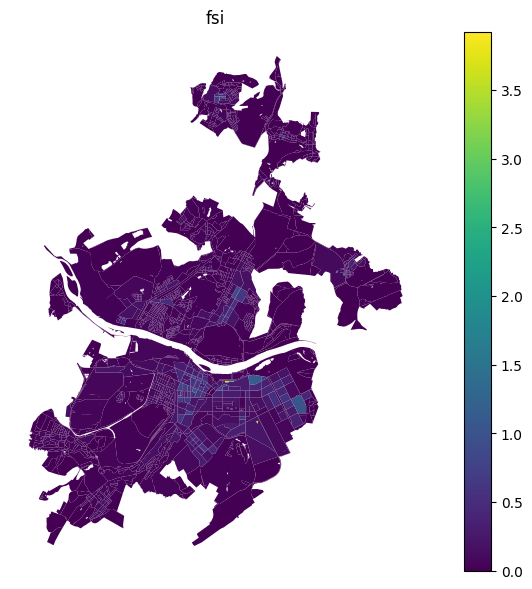

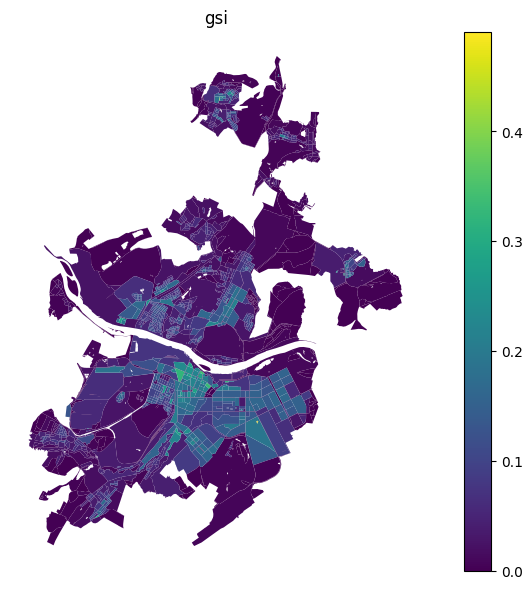

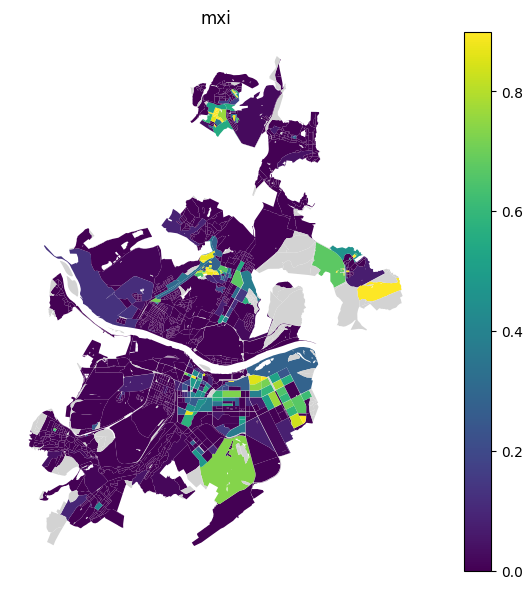

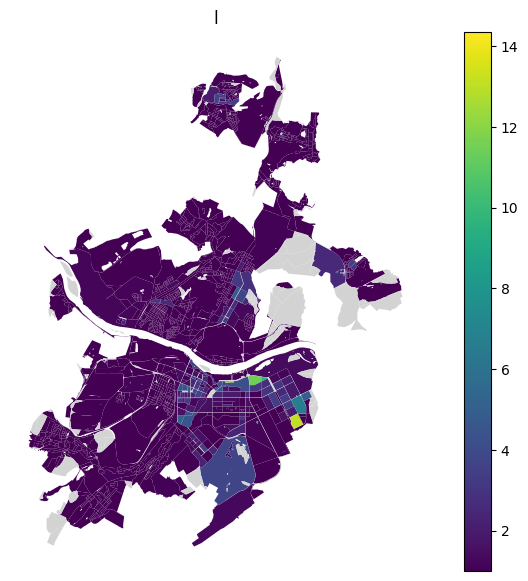

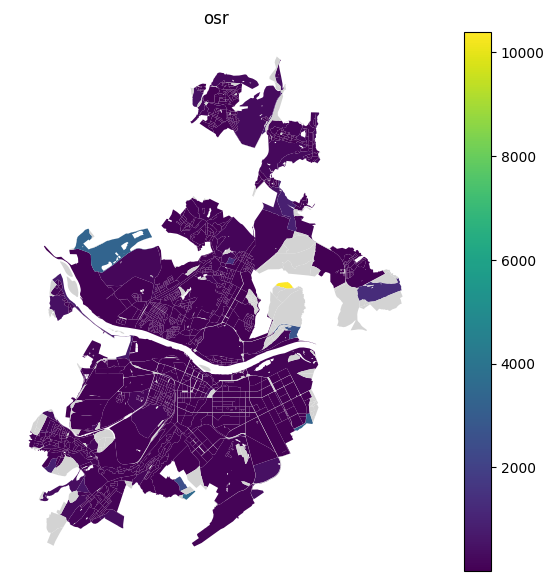

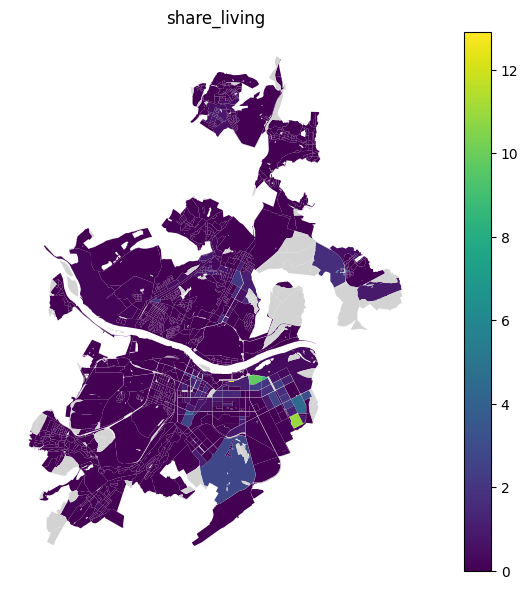

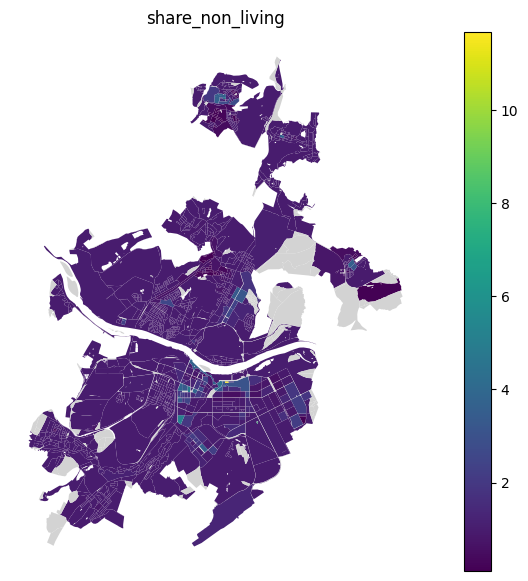

,fsi,gsi,mxi,l,osr,share_living,share_non_living
block_id,,,,,,,
978,0.000096,0.000096,0.0,1.0,10393.784601,0.0,1.0
813,0.077600,0.077600,0.0,1.0,11.886664,0.0,1.0
1920,3.927155,0.490894,0.0,8.0,0.129637,0.0,8.0


In [17]:
require_metrics()
density = blocks[['geometry']].join(calculate_density_indicators(buildings_blocks.copy()))
density_cols = ['fsi','gsi','mxi','l','osr','share_living','share_non_living']
density[density_cols] = density[density_cols].replace([np.inf,-np.inf],np.nan)
density['density_defined'] = (density.build_floor_area > 0) & (density.footprint_area > 0)
show_numeric(density, density_cols)
display(density.loc[density.density_defined, density_cols].sort_values('fsi').iloc[
    sorted(set([0, len(density[density.density_defined])//2, max(0,len(density[density.density_defined])-1)]))])
save_geo(density, RESULTS / 'density.geojson','block_id')

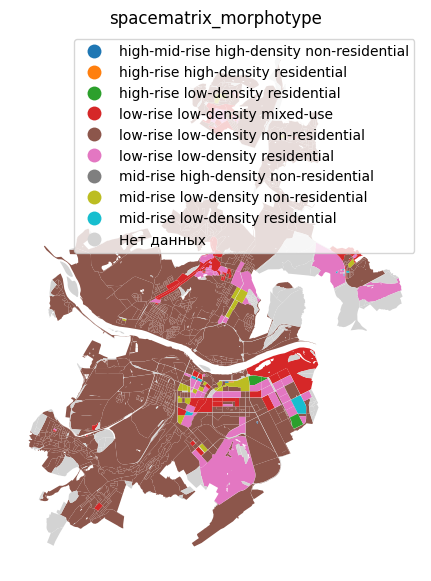

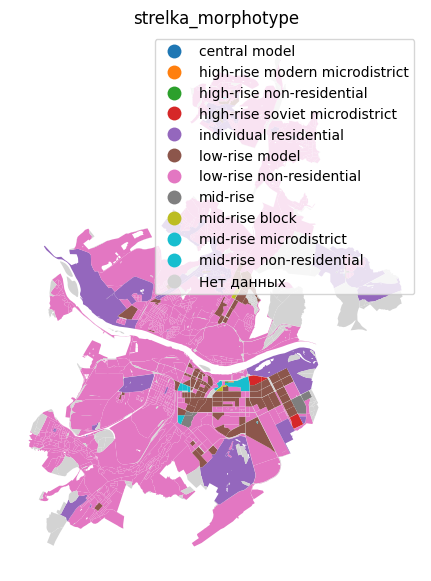

,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.060892,0.900000,low-rise,low-density,residential,low-rise low-density residential
1,1.000000,0.070958,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
2,2.790056,0.419332,0.576041,low-rise,low-density,residential,low-rise low-density residential
3,9.840826,3.835700,0.000000,high-mid-rise,high-density,non-residential,high-mid-rise high-density non-residential
4,4.746257,0.905175,0.887769,mid-rise,low-density,residential,mid-rise low-density residential
5,11.419419,0.696541,0.855156,high-rise,low-density,residential,high-rise low-density residential
6,1.868245,0.298276,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
7,14.345295,2.599994,0.900000,high-rise,high-density,residential,high-rise high-density residential
8,1.000000,0.087215,0.377008,low-rise,low-density,mixed-use,low-rise low-density mixed-use


strelka_morphotype,central model,high-rise modern microdistrict,high-rise non-residential,high-rise soviet microdistrict,individual residential,low-rise model,low-rise non-residential,mid-rise,mid-rise block,mid-rise microdistrict,mid-rise non-residential
spacematrix_morphotype,,,,,,,,,,,
high-mid-rise high-density non-residential,0,0,1,0,0,0,0,0,0,0,1
high-rise high-density residential,0,1,0,0,0,0,0,0,0,0,0
high-rise low-density residential,0,0,0,3,0,0,0,0,0,0,0
low-rise low-density mixed-use,0,0,0,0,27,25,0,0,0,0,0
low-rise low-density non-residential,0,0,0,0,20,24,1092,0,0,0,0
low-rise low-density residential,0,0,0,0,41,44,0,2,0,0,0
mid-rise high-density non-residential,0,0,0,0,0,0,0,0,0,0,1
mid-rise low-density non-residential,0,0,0,0,0,6,12,0,2,2,5
mid-rise low-density residential,1,0,0,0,0,2,0,5,0,0,0


In [18]:
require_metrics()
morph_input = density.loc[density.density_defined, ['l','fsi','mxi']].dropna()
N_CLUSTERS = 11
assert len(morph_input.drop_duplicates()) >= N_CLUSTERS, 'Недостаточно разных кварталов для 11 кластеров'
spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(morph_input, n_clusters=N_CLUSTERS, random_state=42)
strelka_df = get_strelka_morphotypes(morph_input)
morphotypes = blocks[['geometry']].join(spacematrix_df[['cluster','morphotype']].rename(
    columns={'cluster':'spacematrix_cluster','morphotype':'spacematrix_morphotype'})).join(
    strelka_df[['morphotype']].rename(columns={'morphotype':'strelka_morphotype'}))
show_metric(morphotypes,'spacematrix_morphotype',True)
show_metric(morphotypes,'strelka_morphotype',True)
display(spacematrix_clusters)
display(pd.crosstab(morphotypes.spacematrix_morphotype,morphotypes.strelka_morphotype))
spacematrix_clusters.to_csv(RESULTS / 'spacematrix_clusters.csv',index_label='cluster')
save_geo(morphotypes, RESULTS / 'morphotypes.geojson','block_id')

## 11. Доступность с учётом площади
Формула a9: сумма (время до квартала × площадь квартала) / сумма площадей.
Это среднее время, а не площадь в пределах изохроны. Чем меньше значение, тем ближе
квартал к остальной территории с учётом площади. Наличие недостижимого квартала делает
такое среднее бесконечным; в GeoJSON это `null` с отдельным признаком, без подмены нулём.

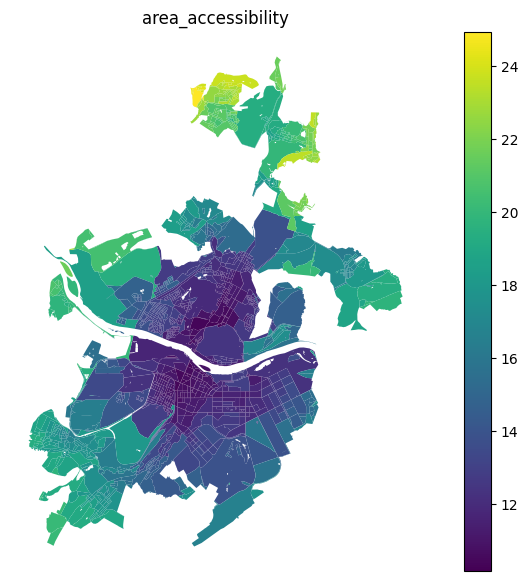

,area_accessibility,all_destinations_reachable
block_id,,
2096,10.158598,True
1891,10.158598,True
2030,10.211604,True
386,10.310041,True
1878,10.326595,True
530,10.341132,True
1865,10.343453,True
1850,10.349275,True
1864,10.349410,True


In [19]:
require_metrics()
area_df = area_accessibility(acc_mx, buildings_blocks[['site_area']])
area_result = blocks[['geometry']].join(area_df)
area_result['all_destinations_reachable'] = np.isfinite(acc_mx.to_numpy()).all(axis=1)
area_result['area_accessibility'] = area_result.area_accessibility.replace([np.inf,-np.inf],np.nan)
show_metric(area_result,'area_accessibility')
display(area_result.drop(columns='geometry').sort_values('area_accessibility').head(10))
save_geo(area_result, RESULTS / 'area_accessibility.geojson','block_id')

## 12. Итоговый набор и контроль полноты
Каждый числовой показатель показан таблицей и картой в своей секции. Итоговый GeoJSON
объединяет результаты по постоянному `block_id`, имена зданий и школ имеют разные префиксы.
Матрица, межквартальные связи и характеристики кластеров сохраняются отдельно.
Таблица полноты нужна для следующего этапа — создания отдельного Python-скрипта дашборда.
HTML пока не создаётся: сначала выполните расчёты и проверьте результаты.

In [12]:
require_metrics()
# Сборку итогового набора можно повторить из сохранённых результатов без георасчётов.
saved_layers = {'landuse':'landuse.geojson','buildings_blocks':'buildings.geojson',
 'schools_blocks':'schools.geojson','provision':'provision.geojson','density':'density.geojson',
 'morphotypes':'morphotypes.geojson','area_result':'area_accessibility.geojson',
 'graph_attachment':'graph_attachment.geojson'}
for variable, filename in saved_layers.items():
    if variable not in globals(): globals()[variable] = read_blocks(RESULTS / filename, CRS)
density_cols = ['fsi','gsi','mxi','l','osr','share_living','share_non_living']
norm_demand = int(service_types_config['school']['demand'])
norm_accessibility = int(service_types_config['school']['accessibility'])
N_CLUSTERS = len(pd.read_csv(RESULTS / 'spacematrix_clusters.csv'))
combined = blocks[['geometry','site_area']].copy()
groups = {
 'landuse':(landuse.drop(columns=['site_area'],errors='ignore'),'landuse_'),
 'buildings':(buildings_blocks.drop(columns=['site_area'],errors='ignore'),'building_'),
 'schools':(schools_blocks,'school_'), 'provision':(provision,'provision_'),
 'density':(density[density_cols+['density_defined']],'density_'),
 'morphotypes':(morphotypes,''), 'accessibility':(area_result,''),
 'graph_quality':(graph_attachment,'transport_')}
manifest = []
for group,(frame,prefix) in groups.items():
    columns = [c for c in frame.columns if c not in ['geometry','block_id']]
    assert frame.index.equals(blocks.index), group
    combined = combined.join(frame[columns].add_prefix(prefix))
    for col in columns:
        manifest.append({'group':group,'indicator':prefix+col,'notebook_section':group,
                         'dashboard_location':'dashboard.html: карта, распределение и общая таблица'})
save_geo(combined,RESULTS / 'blocks_metrics.geojson','block_id')
pd.DataFrame(manifest).to_csv(RESULTS / 'indicator_manifest.csv',index=False)
save_json({'territory':QUERY,'created_utc':datetime.now(timezone.utc).isoformat(),
    'versions':versions,'working_crs':str(CRS),'graph_source':GRAPH_SOURCE,'graph_snapshot':GRAPH_DATE,
    'population_calibration':json.loads((RESULTS / 'population_calibration.json').read_text(encoding='utf-8')),
    'mode':'drive','off_network_access_time_included':False,
    'far_snap_over_1000m_count':int(graph_attachment.far_snap_over_1000m.sum()),
    'maximum_snap_distance_m':float(graph_attachment.snap_distance_m.max()),
    'source_pbf':json.loads((RAW / 'RU-KEM.metadata.json').read_text(encoding='utf-8')),
    'normative_school_demand_per_1000':norm_demand,
    'normative_school_accessibility_min':norm_accessibility,
    'assumptions':{'default_floors':1,'living_area_coefficient':.9,'living_area_per_person':30,
                   'provision_max_depth':1,'spacematrix_n_clusters':N_CLUSTERS},
    'limitations':['OSM incompleteness','modelled population','imputed school capacity',
                  'drive scenario is not pedestrian school accessibility','graph boundary coverage checked manually']},
    RESULTS / 'study_metadata.json')
restored = read_blocks(RESULTS / 'blocks_metrics.geojson', CRS)
assert restored.index.equals(combined.index)
for col in combined.select_dtypes(include='number'):
    np.testing.assert_allclose(restored[col],combined[col].replace([np.inf,-np.inf],np.nan),equal_nan=True)
display(pd.DataFrame(manifest))
print('Сохранено:',RESULTS)

,group,indicator,notebook_section,dashboard_location
0,landuse,landuse_residential,landuse,"dashboard.html: карта, распределение и общая т..."
1,landuse,landuse_business,landuse,"dashboard.html: карта, распределение и общая т..."
2,landuse,landuse_recreation,landuse,"dashboard.html: карта, распределение и общая т..."
3,landuse,landuse_industrial,landuse,"dashboard.html: карта, распределение и общая т..."
4,landuse,landuse_transport,landuse,"dashboard.html: карта, распределение и общая т..."
5,landuse,landuse_special,landuse,"dashboard.html: карта, распределение и общая т..."
6,landuse,landuse_agriculture,landuse,"dashboard.html: карта, распределение и общая т..."
7,landuse,landuse_land_use,landuse,"dashboard.html: карта, распределение и общая т..."
8,landuse,landuse_share,landuse,"dashboard.html: карта, распределение и общая т..."
9,landuse,landuse_landuse_overlap_flag,landuse,"dashboard.html: карта, распределение и общая т..."


Сохранено: C:\Users\kkosh\OneDrive\Документы\ITMOAI\python-package-boilerplate\data\kemerovo\results


## 13. Выводы после уточнения населения

Контрольная численность — **542 928 человек**, предоставлена пользователем; год статистики
не указан. Значения по кварталам — расчётное пропорциональное распределение. Исходная модель
158 384 сохранена отдельно. Целочисленная сумма по 2230 кварталам точно равна 542 928.

При нормативе 120 школьных мест на 1000 жителей спрос по кварталам составил **65 268 мест**.
Сумма больше 542 928 × 0.12 из-за округления спроса вверх отдельно в каждом квартале,
как в примере BlocksNet. С учётом модельной вместимости 112 школ (**28 000 мест**)
неудовлетворённый спрос составил **37 268 мест**, свободных мест — **0**.
Прежний вывод о полном удовлетворении спроса заменён этим результатом.

Численность кварталов остаётся модельной: 95.8% зданий не имели этажности в OSM.
Вместимость всех школ восстановлена, поэтому результат не является официальной оценкой
дефицита. Плотность застройки, морфотипы, матрица времени и геометрия кварталов не зависят
от этой корректировки населения. Карты населения, обеспеченности, связи спроса, GeoJSON
и HTML обновлены согласованно. Набор включает 54 поля показателей и качества.

## Повторный запуск в PowerShell

Из корня проекта:
```powershell
.\.venv\Scripts\python.exe scripts\run_study.py
.\.venv\Scripts\python.exe scripts\build_dashboard.py
```
Первый скрипт выполняет ноутбук в текущем процессе с сохранением результатов ячеек.
При `REFRESH=False` исходные слои и кварталы читаются из файлов; при `REUSE_MATRIX=True`
матрица читается из Parquet после сверки входных контрольных сумм. Остальные аналитические
секции пересчитываются, поэтому для одного только HTML используйте вторую команду.
`--until-blocks` у `run_study.py` останавливает выполнение после подготовки кварталов.

Матрица дополнительно сохранена в `travel_time_rows.geojson`: каждый Feature — точка начала
и массив `time_min`; его позиции соответствуют общему `target_block_ids` коллекции.
Точность представления GeoJSON и HTML — 0.01 минуты; Parquet сохраняет исходные float32.

## Файлы и полнота
`indicator_manifest.csv` перечисляет 54 поля итогового GeoJSON. Все они доступны в карте,
распределении и общей таблице HTML. Отдельные секции содержат матрицу времени, связи спроса
и характеристики кластеров. `scripts/build_dashboard.py` читает готовые результаты и не загружает
данные, не запускает BlocksNet или оптимизацию.

## Источники и журнал решений
- Методички практик 1–2 и официальный `aimclub/blocksnet/examples/pipeline.ipynb`.
- Граница: Nominatim / OSM, relation 1312868; точный контур сохранён в GeoJSON.
- Слои: OpenStreetMap через региональную выгрузку OSMLab `RU-KEM.pbf`,
  https://www.osmlab.ru/regions/RU-KEM.pbf. Метаданные файла и SHA256 сохранены.
- Overpass-серверы вернули SSL/413/504, поэтому выбран локальный PBF.
- Готовый архив графов Harvard Dataverse вернул 403. **Пользователь отдельно разрешил**
  автомобильный граф OSM. Использованы исходные ID узлов, drive-фильтр OSMnx, его оценки
  скоростей и времени; интермодальный граф не строился.
- Проверены нарезка, дальние привязки, региональные ошибки геометрии, баланс мест,
  соответствие идентификаторов и повторное чтение GeoJSON.
- `.venv` и исходный `my_package` сохранены. Публикация на GitHub не выполнялась.
